# C2 evaluation - diffusion counterfactuals

The same figures as `C2_evaluation.ipynb`, read off the **generated** counterfactual arm.
Nothing is retrained here; this reads the fold predictions written by
`c2_train_attributes.py` / `c2_train_images.py`.

**What differs from the KNN notebook**

| | `C2_evaluation.ipynb` | this notebook |
|---|---|---|
| counterfactual | nearest correctly-classified train image | FastDiME trajectory from the query itself |
| `SOURCE` | `knn_correct_cf` | `diffusion_hml_sub20k` |
| rows | the whole C2 table (~80-92k) | the frozen 20,000-image subset |
| **K means** | how many *neighbours* are retrieved | how many *intensity levels* are used |

That last row is the one to keep in mind. K is not a neighbourhood size here: the three
counterfactuals of a query are the same edit at three strengths, ordered `high, mid, low`, so
K=1 is the strongest edit alone and K=3 adds the two weaker ones. Slot 0 is `high` at both K,
which is what makes K=1 a strict prefix of K=3.

**Sections 1b and 1d are the comparison against the KNN arm** - the figure this whole
experiment exists to produce. Both arms are built on the same 20,000 rows, the same
patient-grouped folds and the same seed, so the counterfactual source is the only thing that
differs. Each of those figures draws the two arms on an absolute AUROC axis, one line per arm.

Every comparison panel checks `same_rows` first and refuses to draw if the two arms do not
cover the identical images. Run `c2_compare_arms.py` for the stronger version of that check -
it verifies the fold assignment too, not just the row set.

**Statistics** come from `bootstrapping_diffusion.ipynb`, in the same shape, with the same
comparisons and the same Holm families as `bootstrapping.ipynb` for the KNN arm.

The two aims, and the sections, are unchanged.

**Aim 1 - is there correctness signal in counterfactuals?** Every attribute config (1a) and
every CNN variant (1c) on an absolute AUROC scale, as itself rather than as a difference, then
each of those against the KNN arm (1b, 1d).

As in the KNN notebook, Aim 1 first **builds** the model, then **tests** it. 1a and 1c build
it: every config at every K (1, 3). That is the only place K is compared, and it picks the
final system, `I+C+D` and `dual_sal` at K=1 (`FINAL`). 1f and 1g test it: at K=1, does adding
the counterfactual beat the input alone? Everything from 1f on is at `FINAL["k"]` = 1.

**Aim 2 - is it better than the baseline?** The final system -- `I+C+D`, `dual_sal` and their
ensemble, at K=1, fixed in advance -- against MSP, then the two combined.

**The baseline is MSP**, straight off C0 with nothing fitted on top, in the
`MSP_VARIANT = "threshold"` form: the probability of the class C0 actually predicted at
its Youden threshold. C0 does not predict at 0.5, so plain `max(p, 1-p)` measures distance
from a decision it never makes. This matches `C2_evaluation.ipynb` -- it has to, or the two
notebooks draw different reference lines and their Aim 2 gaps cannot be compared. It is drawn
as a thin grey dashed reference everywhere and is never a series colour.

**The attribute models are probability-free** (`c2_train_attributes.py`, block ablation):
**I** = the query's attributes + C0 embedding, **C** = the counterfactual's, **D** = query minus
counterfactual, and the combinations I+C and I+C+D. C0's probability is in none of them.

## Setup

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score

sys.path.insert(0, os.path.abspath("code"))
from c2_msp import MSP_VARIANTS, msp_score

# Which MSP baseline every figure is drawn against. MUST match C2_evaluation.ipynb,
# or the two notebooks draw different reference lines and their Aim 2 gaps are not
# comparable -- "threshold" is worth +0.02-0.045 AUROC over plain max(p, 1-p), which
# is larger than most of the effects being measured.
MSP_VARIANT = "threshold"

# K = number of INTENSITY LEVELS the counterfactual features are pooled over, not a
# neighbourhood size. The levels are ordered high, mid, low, so K=1 is the strongest
# edit alone and K=3 adds the two weaker ones. K_VALUES is compared ONLY in the Aim 1 line
# plots (1a, 1c); everything else -- the 1f/1g ablations and Aim 2 -- is at FINAL["k"].
K_VALUES = [1, 3]
K_LEVELS = {1: "high", 3: "high+mid+low"}

# The final system, as in C2_evaluation.ipynb: each family's ablation winner at one K. K=1
# beats K=3 for both models on every disease (1a, 1c). Must match FINAL in
# bootstrapping_diffusion.ipynb, which the bootstrap cell checks.
FINAL = {"k": 1, "attr": "I+C+D", "cnn": "dual_sal", "prob": False}

RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")

# The arm. SOURCE is the only directory component that distinguishes it from the KNN
# arm, so changing this line is the whole difference between the two notebooks.
SOURCE, POLICY = "diffusion_hml_sub20k", "ignore"

# The comparator. Same 20,000 rows, same folds, same seed -- the ONLY difference is
# where the counterfactual came from. That is what makes the paired figures below a
# statement about counterfactuals rather than about two unrelated experiments, and
# `same_rows` checks it rather than assuming it.
KNN_SOURCE = "knn_correct_cf_sub20k"

SUBSET   = "20k"
DISEASES = ["atelectasis", "cardiomegaly", "consolidation", "edema", "effusion"]

CNN_KEYS   = ["xi", "xi_sal", "cf", "cf_sal", "dual", "dual_sal", "dual_sal_scalars"]
CNN_GROUPS = [["xi", "xi_sal", "cf", "cf_sal"], ["dual", "dual_sal", "dual_sal_scalars"]]
# The image models that never see a counterfactual. Shaded in the CNN ladder, and the
# reason their K lines coincide: with no CF input there is nothing for K to vary.
CNN_NO_CF  = ["xi", "xi_sal"]
# Tick labels in the attribute notation, so CNN and attribute figures read side by side:
# I = query image, C = counterfactual image, Sal = saliency maps. Keys stay the model names.
CNN_LABELS = {"xi": "I", "xi_sal": "I+Sal", "cf": "C", "cf_sal": "C+Sal",
              "dual": "I+C", "dual_sal": "I+C+Sal", "dual_sal_scalars": "I+C+Sal+P"}

# Canonical config order -- NOT sorted by performance, so a config sits at the same x
# in every panel and the eye can track it across diseases. Single blocks | combinations.
CONFIG_GROUPS = [["I", "C", "D"], ["I+C", "I+C+D"]]
# I never sees a counterfactual: the shaded control in every attribute figure.
ATTR_NO_CF = ["I"]
CONFIG_ORDER = [c for g in CONFIG_GROUPS for c in g]

# Thesis-wide style: colour = model family, lightness = how much counterfactual a model
# sees, figures drawn at print size. See code/thesis_style.py.
import importlib, thesis_style
importlib.reload(thesis_style)     # pick up edits to the style file without a kernel restart
from thesis_style import *
apply()

# K lines take the MODEL family's ramp, as in C2_evaluation.ipynb: attributes blue, CNN
# red, light to dark as K grows -- so the same figure in the two notebooks reads the same.
# The green trajectory ramp is only for the trajectory models, which are their own family.
# The arm comparisons draw BOTH arms in the family colour of the models compared (attribute
# blue, CNN red) -- a second hue would read as a second model family -- and tell the arms
# apart by line style and marker only.
BLUE, RED, TRAJ = FAMILY["attr"], FAMILY["cnn"], FAMILY["traj"]
K_COLOR   = k_colors("traj", K_VALUES)       # trajectory ladder only
ARMS      = {"diffusion": SOURCE, "KNN": KNN_SOURCE}
# Shape as well as dash: the two arms overlap almost everywhere, and where the lines sit
# on top of each other the circles and squares still separate them.
ARM_MARKER = {"diffusion": "o", "KNN": "s"}

# Diffusion is marked by LINE STYLE, not colour: colour already means model family (and
# light-to-dark means K), exactly as in C2_evaluation.ipynb. So a diffusion figure is the
# KNN figure with dashed lines and hatched bars, and a reader who has learnt one reads the
# other. In the arm comparisons KNN stays solid, so the dash alone separates the arms.
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
DIFF_LS    = "--"
DIFF_HATCH = "///"
ARM_LS     = {"diffusion": DIFF_LS, "KNN": "-"}
plt.rcParams["hatch.linewidth"] = 0.6


def hatch_edge(color):
    """Hatch colour for a bar: faint ink on a tint, white on a full-strength colour --
    the same rule as the value labels, so the hatch stays visible on both."""
    return to_rgba(INK, 0.3) if color in TINT.values() else to_rgba("white", 0.8)


def diff_bar(ax, x, h, color, **kw):
    """ax.bar for one diffusion bar: hatched, no outline."""
    return ax.bar(x, h, color=color, hatch=DIFF_HATCH, edgecolor=hatch_edge(color),
                  linewidth=0, **kw)


def diff_patch(color, label):
    """Legend entry for a hatched bar (patch_handle is a marker and cannot carry a hatch)."""
    return Patch(facecolor=color, hatch=DIFF_HATCH, edgecolor=hatch_edge(color), lw=0,
                 label=label)


# Every figure is also written to FIG_DIR, ready to upload to Overleaf as one folder. Both
# C2 notebooks write to the SAME folder and are told apart by FIG_PREFIX. PDF is vector (use
# it in \includegraphics); PNG is a 600-dpi raster copy (savefig.dpi in thesis_style).
FIG_DIR     = os.path.join("figures", "c2")
FIG_PREFIX  = "diffusion"
FIG_FORMATS = ("pdf", "png")


def save_fig(fig, name):
    """Write `fig` as FIG_DIR/<FIG_PREFIX>_<name>.<ext>. No-op for None (nothing drawn yet)."""
    if fig is None:
        return
    os.makedirs(FIG_DIR, exist_ok=True)
    for ext in FIG_FORMATS:
        fig.savefig(os.path.join(FIG_DIR, f"{FIG_PREFIX}_{name}.{ext}"))


# The key-figure versions of the points figures (average large, diseases small) go to their
# own folder under the SAME names as the grid versions, so swapping one for the other in the
# thesis is a change of folder only. PDF + PNG (the PNG for slides).
KEY_FIG_DIR = os.path.join("figures", "c2_key")


def save_key_fig(fig, name):
    """Write `fig` as KEY_FIG_DIR/<FIG_PREFIX>_<name>.{pdf,png}. No-op for None."""
    if fig is None:
        return
    os.makedirs(KEY_FIG_DIR, exist_ok=True)
    for ext in FIG_FORMATS:
        fig.savefig(os.path.join(KEY_FIG_DIR, f"{FIG_PREFIX}_{name}.{ext}"))

print(f"arm: {SOURCE}  ({FAMILY_LABEL['traj']})   MSP: {MSP_VARIANT}")
print(f"diseases: {', '.join(DISEASES)}")

arm: diffusion_hml_sub20k  (trajectory)   MSP: threshold
diseases: atelectasis, cardiomegaly, consolidation, edema, effusion


## Loaders

In [2]:
# Every loader takes `source`, defaulting to this notebook's arm. That one argument is
# what lets the comparison figures read the KNN arm with the identical code path -- a
# second set of loaders is how the two arms would quietly stop being read the same way.
def attr_dir(d, k=None, source=None):
    return os.path.join(C2, d, source or SOURCE, f"cf_{k or FINAL['k']}", "attributes")

def cnn_dir(d, key, k=None, source=None):
    return os.path.join(C2, d, source or SOURCE, f"cf_{k or FINAL['k']}", "images", key)

def load_attributes(disease, k=None, n_folds=5, source=None):
    """Pooled out-of-fold attribute predictions for one K; `fold` kept so per-fold means
    stay available. Returns None if that K has not finished, so a partially run sweep
    still renders -- which matters here, where K=3 needs the mid and low levels to have
    been materialised."""
    parts = []
    for i in range(n_folds):
        p = os.path.join(attr_dir(disease, k, source), f"fold_{i}_predictions.csv")
        if not os.path.exists(p):
            return None
        f = pd.read_csv(p); f["fold"] = i
        parts.append(f)
    return pd.concat(parts, ignore_index=True)

def load_cnn(disease, k=None, n_folds=5, source=None):
    """Pooled OOF CNN predictions, one column per FINISHED model (fold_aucs.csv present),
    so the notebook works mid-run.

    Columns are renamed `cnn_<key>`: the `cf` model writes `cf_prob`, which collides with
    the attribute frame's own `cf_prob` (mean counterfactual C0 probability) on merge.
    """
    out = None
    for key in CNN_KEYS:
        if not os.path.exists(os.path.join(cnn_dir(disease, key, k, source), "fold_aucs.csv")):
            continue
        parts = []
        for i in range(n_folds):
            p = os.path.join(cnn_dir(disease, key, k, source), f"fold_{i}_predictions.csv")
            if not os.path.exists(p): break
            f = pd.read_csv(p); f["fold"] = i
            parts.append(f)
        else:
            df = (pd.concat(parts, ignore_index=True)
                    [["path", "patient_id", "correct", "fold", f"{key}_prob"]]
                    .rename(columns={f"{key}_prob": f"cnn_{key}"}))
            out = df if out is None else out.merge(df[["path", f"cnn_{key}"]],
                                                   on="path", how="outer")
    return out

def msp(df, disease, variant=None):
    """Maximum softmax probability -- the untrained baseline. Nothing is fitted.
    `variant` defaults to MSP_VARIANT; the threshold is only read when a variant needs it."""
    variant = variant or MSP_VARIANT
    p = df[f"{disease}_prob"].values
    t = None if variant == "standard" else c0_threshold(disease)
    return msp_score(p, t, variant)

def config_cols(df, model="MLP"):
    """Config -> column, in CONFIG_ORDER. Configs absent from the file are skipped."""
    have = {c.split("_", 1)[1].rsplit("_prob", 1)[0]: c
            for c in df.columns if c.startswith(f"{model}_") and c.endswith("_prob")}
    return {c: have[c] for c in CONFIG_ORDER if c in have}

def c0_threshold(disease, policy=POLICY):
    p = os.path.join(RESULTS, "C0_final", f"multilabel_{policy}", disease, "threshold.txt")
    return float(open(p).read().strip())

def per_fold_auc(df, score_col_or_values):
    """Mean AUROC over the 5 folds -- the same statistic cv_summary.csv reports."""
    v = df[score_col_or_values] if isinstance(score_col_or_values, str) else pd.Series(
        score_col_or_values, index=df.index)
    return float(np.mean([roc_auc_score(g["correct"], v.loc[g.index])
                          for _, g in df.groupby("fold")]))

def panel_note(df, disease, policy=POLICY):
    """Per-panel subtitle: sample count and C0's error profile.

    n is ~20,000 on every disease here, not the full table: this arm is restricted to
    the frozen subset the counterfactuals were generated for. It is still not identical
    across diseases, because rows with an uncertain (-1) CheXpert label have no defined
    correctness and are dropped before the subset is taken.

    FP/FN split C0's errors by the class it predicted. Neither `pred` nor `true` is stored
    in the fold predictions, but both are recoverable: pred = prob >= threshold, and since
    `correct` is exactly (pred == true), a wrong row has true = 1 - pred.
    """
    corr = df["correct"].values.astype(int)
    pred = (df[f"{disease}_prob"].values >= c0_threshold(disease, policy)).astype(int)
    n  = len(df)
    fp = ((pred == 1) & (corr == 0)).sum() / n
    fn = ((pred == 0) & (corr == 0)).sum() / n
    return f"n={n:,}  ·  C0 err {1 - corr.mean():.1%}  (FP {fp:.1%} / FN {fn:.1%})"

def available():
    """What has finished, per disease and K. Run this first -- the arm is built
    incrementally and an empty figure is otherwise indistinguishable from a bad path."""
    rows = []
    for d in DISEASES:
        for k in K_VALUES:
            a = load_attributes(d, k)
            c = load_cnn(d, k)
            rows.append({"disease": d, "K": k,
                         "attributes": "-" if a is None else f"{len(a):,} rows",
                         "CNN models": "-" if c is None else
                                       sum(c[f"cnn_{x}"].notna().all()
                                           for x in CNN_KEYS if f"cnn_{x}" in c.columns)})
    return pd.DataFrame(rows)

available()

,disease,K,attributes,CNN models
0,atelectasis,1,"20,000 rows",7
1,atelectasis,3,"20,000 rows",7
2,cardiomegaly,1,"20,000 rows",7
3,cardiomegaly,3,"20,000 rows",7
4,consolidation,1,"20,000 rows",7
5,consolidation,3,"20,000 rows",7
6,edema,1,"20,000 rows",7
7,edema,3,"20,000 rows",7
8,effusion,1,"20,000 rows",7
9,effusion,3,"20,000 rows",7


# Aim 1 - is there correctness signal in counterfactuals?

Nothing in this section is a comparison against the baseline; that is Aim 2. Each config is
plotted at **its own AUROC**, so the reading is "how well does this set of inputs rank C0's
errors" rather than "how much does it add". The shape of the line across configs is the thing:
it says which inputs carry the signal, and in particular what the counterfactual blocks
(`C`, `D`, `I+C`, `I+C+D`) buy over the query-only one (`I`).

**One line per K** - here, per number of intensity levels. K=1 is the `high` counterfactual
alone; K=3 pools `high`, `mid` and `low`. Asking whether K helps is asking whether the weaker
edits carry information the strong one does not. A K that has not finished is simply absent
from the panel. **This is the only place K is compared**: the K these plots pick,
`FINAL["k"]` = 1, is the K of every figure from 1f on.

MSP is drawn as thin grey horizontal lines - threshold-adjusted (dashed) and plain
max(p, 1-p) (dotted) - references, not series.

**Each panel gets its own y range**, computed from that panel's own configs, because the
differences that matter are thousandths of AUROC and one range wide enough for three diseases
flattens them. The absolute level is in each panel title.

The y range is **fitted** to every config and both MSP lines, with a minimum height of 0.05,
so no value is ever cut off; a config far below the rest stretches its own panel only.

Configs run along x in the canonical `I, C, D | I+C, I+C+D` order rather than by rank, so a
config sits at the same x in every panel; a hairline separates single blocks from combinations.
`I` sees no counterfactual, so its K lines coincide by construction.

### Plot helpers

In [3]:
# Both MSPs as references, as in C2_evaluation.ipynb: the threshold-adjusted one (dashed)
# and plain max(p, 1-p) (dotted). variant -> (legend label, short label for the panel note,
# linestyle).
# Ladder panels are the same width as the points panels (POINTS_PANEL, 50 mm) and the fonts
# stay at print size, so text reads the same size in both; a narrower panel, not a bigger
# font, is what fills it. Taller than POINTS_PANEL for the subtitle and the rotated ticks.
LADDER_PANEL = (50 * MM, 66 * MM)
# The ladders (1a-1d) default to ONE ROW across the full page width: five 37 mm panels,
# legend in a single line beneath. Half the height of the 3-column grid at the same font
# size. Pass ncols=3 to get the grid back. Same as C2_evaluation.ipynb.
ROW_PANEL_H = 62 * MM

MSP_SHOWN = {"threshold": ("ad-MSP",          "ad-MSP", "--"),
             "standard":  ("MSP max(p, 1−p)", "MSP",    ":")}


def msp_bases(df, disease):
    """{variant: mean fold AUROC} for every MSP in MSP_SHOWN, on df's rows."""
    return {v: per_fold_auc(df, msp(df, disease, v)) for v in MSP_SHOWN}


def mean_bases(bases):
    """Average a list of msp_bases dicts, variant by variant."""
    return {v: float(np.mean([b[v] for b in bases])) for v in MSP_SHOWN}


def draw_msp(ax, bases):
    for v, y in bases.items():
        ax.axhline(y, color=GREY, ls=MSP_SHOWN[v][2], lw=LW["ref"], zorder=1)


def msp_handles():
    return [Line2D([], [], color=GREY, ls=ls, lw=LW["ref"], label=lab)
            for lab, _, ls in MSP_SHOWN.values()]


def line_panel(ax, rows, series, groups, ylim, base=None, colors=None, shade=None,
               markers=None, labels=None, ls="-"):
    """One disease: AUROC against config, one line per K.

    `ls` is one linestyle for every series, or {series: linestyle}.
    """
    lo, hi  = ylim
    colors  = colors or K_COLOR
    markers = markers or k_markers(series)
    x       = np.arange(len(rows))
    ax.set_ylim(lo, hi)

    # Shade the reference family rather than only ruling a line after it: a band says
    # "this region is different in kind" where a rule only says "something changes here".
    # `shade` is an explicit config list, not a group index -- in the CNN ladder the
    # models with no counterfactual input are a PREFIX of the first group, so shading
    # group 0 would wrongly cover cf and cf_sal.
    if shade:
        idx = [i for i, c in enumerate(rows) if c in shade]
        if idx:
            ax.axvspan(min(idx) - 0.5, max(idx) + 0.5, color=SHADE, lw=0, zorder=0)

    if base is not None:
        draw_msp(ax, base)

    seen = 0
    for g in groups[:-1]:
        seen += sum(1 for c in g if c in rows)
        if 0 < seen < len(rows):
            ax.axvline(seen - 0.5, color=HAIR, lw=LW["axis"], zorder=0)

    for k, vals in series.items():
        y    = np.array([vals.get(c, np.nan) for c in rows], float)
        ax.plot(x, y, ls=ls[k] if isinstance(ls, dict) else ls,
                marker=markers[k], ms=4.5, lw=LW["line"],
                mec="white", mew=0.5, color=colors[k], zorder=3, label=f"K={k}")

    # Rows are the GLOBAL config list, identical in every panel, so a config keeps its x
    # position across diseases and a missing one leaves a gap rather than shifting the rest.
    ax.set_xticks(x); ax.set_xticklabels([(labels or {}).get(r, r) for r in rows], fontsize=FS["small"],
                       rotation=45, ha="right", rotation_mode="anchor")
    ax.set_xlim(-0.5, len(rows) - 0.5)
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))
    # Square PLOTTING AREA. set_box_aspect fixes the axes box, where a square figsize would
    # only fix the cell and let the labels squash the plot inside it. Not set_aspect("equal"),
    # which equalises data units -- x spans 16 config slots against y's ~0.05 AUROC.
    ax.set_box_aspect(1)
    return ax


def k_legend(ks, colors=None, shade_label="no counterfactual input", ls="-"):
    colors  = colors or K_COLOR
    markers = k_markers(ks)
    lines   = [line_handle(colors[k], f"K={k} ({K_LEVELS[k]})", markers[k]) for k in ks]
    for h in lines:
        h.set_linestyle(ls)
    return (lines
            + [patch_handle(SHADE, shade_label),
               *msp_handles()])


def _grid(n, ncols, panel=(FULL / 3, 76 * MM)):
    """Axes grid with the unused trailing cells removed. Cells are taller than wide even
    though the axes are square: the extra height is what the x labels and the
    title lines consume."""
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel[0] * ncols, panel[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.remove()
    return fig, axes[:n]


def corner_legend(fig, n, ncols, handles):
    """Legend in the empty bottom-right cell of an n-panel grid; beneath the figure
    when the grid is full. Lays the figure out either way."""
    nrows = int(np.ceil(n / ncols))
    if n < nrows * ncols:
        lax = fig.add_subplot(nrows, ncols, nrows * ncols)
        lax.axis("off")
        lax.legend(handles=handles, loc="center", ncol=1, frameon=False)
        square_tight_layout(fig)
    else:
        fig.legend(handles=handles, loc="lower center", ncol=len(handles),
                   bbox_to_anchor=(0.5, -0.02))
        square_tight_layout(fig, rect=(0, 0.02, 1, 0.99))


def row_grid(n):
    """One row of n panels spanning the full page width."""
    return _grid(n, n, (FULL / n, ROW_PANEL_H))


def row_legend(fig, axes, handles):
    """Lay out a one-row figure: y label on the first panel only, legend in one line just
    beneath the lowest tick label -- anchored to it, so it sits close whatever the labels."""
    for ax in axes[1:]:
        ax.set_ylabel("")
    square_tight_layout(fig, rect=(0, 0.07, 1, 1), w_pad=0.6)
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bottom = min(ax.get_tightbbox(r).transformed(fig.transFigure.inverted()).y0 for ax in axes)
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, bottom),
               frameon=False, handlelength=2.2, columnspacing=1.6)


def square_tight_layout(fig, **kw):
    """tight_layout for figures whose axes use set_box_aspect.

    One pass is not enough: it measures the axes before the aspect squares them, so
    the row gap it leaves is sized for the wrong box, so one row's
    tick labels can run into the next row's title. The second pass measures the squared axes.
    """
    for _ in range(2):
        fig.tight_layout(**kw)


def auroc_ylim(series, base, win=0.05):
    """Y range for one panel: fitted to EVERY value drawn -- all configs and both MSP lines --
    and at least `win` tall.

    Fitted rather than a fixed window anchored at the top: a window clipped the configs
    that fall far below the rest (effusion's C, most of its diffusion CNNs) to the axis
    floor, where their values could no longer be read. The `win` minimum still stops a
    panel whose configs sit within a few thousandths of each other from magnifying noise.
    """
    vals  = [v for d in series.values() for v in d.values() if np.isfinite(v)]
    vals += [b for b in (base or {}).values() if np.isfinite(b)]    # every MSP line drawn
    if not vals:
        return (0.5, 0.5 + win)
    hi = max(vals)
    lo = min(min(vals), hi - win)
    # Breathing room so markers and the baselines never sit exactly on a spine.
    pad = 0.04 * (hi - lo)
    return (lo - pad, hi + pad)


def _panel_title(ax, disease, df, base=None):
    """Panel title: disease, then a small subtitle with n, C0's error profile and MSP."""
    # At print size the one-line note is wider than the panel, and tight_layout then shrinks
    # every axes to make room -- so the FP/FN split goes on its own line.
    note = panel_note(df, disease).replace("  (FP ", "\nFP ").rstrip(")")
    # Only the MSP every config is judged against: both values do not fit the panel width,
    # and an overlong note makes tight_layout shrink the axes. The other line is in the legend.
    # On its own line: appended to the note it ran into the neighbouring panel's subtitle.
    if base and np.isfinite(base.get(MSP_VARIANT, np.nan)):
        note += f"\n{MSP_SHOWN[MSP_VARIANT][1]} {base[MSP_VARIANT]:.3f}"
    # The note grows UPWARD from the axes top (va="bottom"), so the title has to be lifted
    # by one line height per extra note line or the two overlap.
    ax.set_title(disease, pad=13 + note.count("\n") * 1.3 * FS["small"])
    ax.text(0.0, 1.02, note, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=FS["small"], color=MUTED)


# ══════════════════════════════════════════════════════════════════════════════
# ARM COMPARISON
# ══════════════════════════════════════════════════════════════════════════════

def same_rows(a, b):
    """Do two arms' prediction frames cover exactly the same images?

    This is the assumption the whole comparison rests on and it is NOT self-evident:
    the two arms are separate runs against separate fold caches, and a stale cache, a
    re-frozen subset or a half-finished run all produce complete, plausible-looking
    results on different rows. An AUROC difference would then be partly a difference
    in which images were scored, and nothing in the figure would show it.
    """
    return len(a) == len(b) and set(a["path"]) == set(b["path"])


def arm_series(disease, keys, kind="attr", k=None, model="MLP"):
    """{arm: {key: AUROC}} for one disease, plus the reference frame and MSP.

    Returns (series, ref, base, note). `note` is non-empty when something is off --
    a missing arm, or the two arms not covering the same rows -- and the caller
    prints it on the panel rather than silently drawing an unsound comparison.
    """
    series, ref, base, frames = {}, None, None, {}
    for arm, src in ARMS.items():
        att = load_attributes(disease, k, source=src)
        if att is None:
            continue
        if kind == "attr":
            f, cols = att, config_cols(att, model)
            vals = {c: per_fold_auc(f, col) for c, col in cols.items() if c in keys}
        else:
            cnn = load_cnn(disease, k, source=src)
            if cnn is None:
                continue
            # MSP must be scored on the SAME rows as the CNN, so merge and keep one frame.
            f = cnn.merge(att[["path", f"{disease}_prob"]], on="path", how="inner")
            vals = {key: per_fold_auc(f, f"cnn_{key}") for key in keys
                    if f"cnn_{key}" in f.columns and f[f"cnn_{key}"].notna().all()}
        if not vals:
            continue
        series[arm], frames[arm] = vals, f
        if ref is None:
            ref, base = f, msp_bases(f, disease)

    note = ""
    if len(series) < len(ARMS):
        note = f"only {', '.join(series) or 'no arm'} finished"
    elif not same_rows(*frames.values()):
        note = "ARMS COVER DIFFERENT ROWS - not comparable"
    return series, ref, base, note


def arm_compare(keys, kind="attr", groups=None, shade=None, diseases=DISEASES,
                k=None, model="MLP", win=0.05, title="", ncols=None,
                panel=LADDER_PANEL, labels=None):
    """AUROC against config for both arms, one panel per disease.

    The Aim 1 ladder with the ARM as the series dimension instead of K, so it is read
    exactly like the figures above it -- same order, same shading, same MSP references.
    """
    panels = []
    for d in diseases:
        series, ref, base, note = arm_series(d, keys, kind, k, model)
        if series:
            panels.append((d, ref, base, series, note))
    if not panels:
        print(f"neither arm has finished {kind} results yet"); return

    rows = [c for c in keys if any(c in s[a] for _, _, _, s, _ in panels for a in s)]

    arm_color = {a: FAMILY[kind] for a in ARMS}      # one hue: the family being compared
    fig, axes = row_grid(len(panels)) if ncols is None else _grid(len(panels), ncols, panel)
    for ax, (d, ref, base, series, note) in zip(axes, panels):
        line_panel(ax, rows, series, groups or [rows], auroc_ylim(series, base, win),
                   base=base, colors=arm_color, shade=shade, markers=ARM_MARKER,
                   labels=labels, ls=ARM_LS)
        _panel_title(ax, d, ref, base)
        ax.set_ylabel("AUROC")
        if note:
            ax.text(0.5, 0.02, note, transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=FS["small"],
                    color=INK if "DIFFERENT" in note else MUTED,
                    fontweight="bold" if "DIFFERENT" in note else "normal")

    arm_lines = [line_handle(arm_color[a], a, ARM_MARKER[a]) for a in ARMS]
    for a, h in zip(ARMS, arm_lines):
        h.set_linestyle(ARM_LS[a])
    handles = (arm_lines
               + [patch_handle(SHADE, "no counterfactual input (control)"), *msp_handles()])
    if ncols is None:
        row_legend(fig, axes, handles)
    else:
        corner_legend(fig, len(panels), ncols, handles)
    return fig


## 1a. Attribute configs

/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


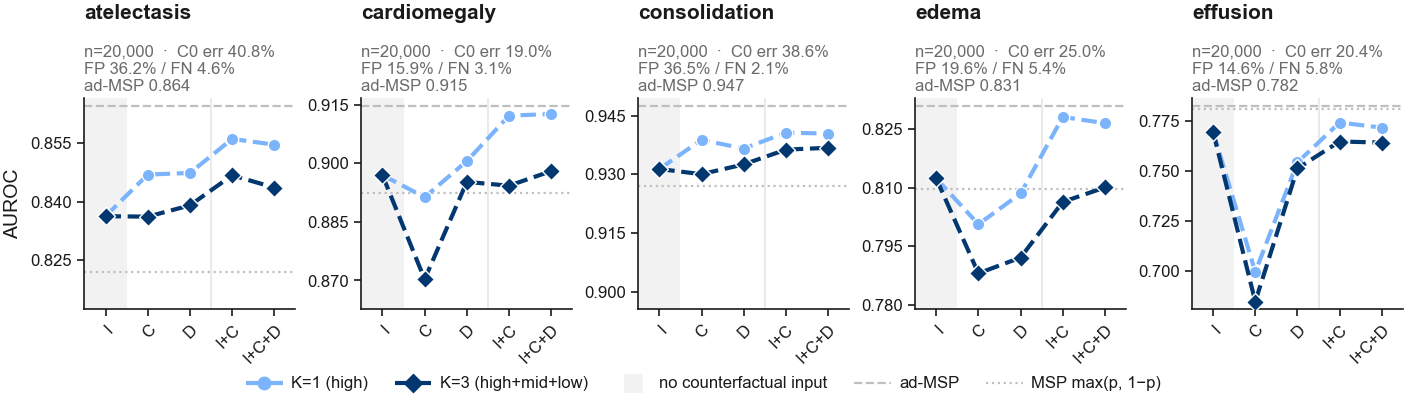

In [4]:
def config_ladder(diseases=DISEASES, model="MLP", ks=None, win=0.05,
                  ncols=None, panel=LADDER_PANEL):
    """AUROC against config, one line per K, one panel per disease."""
    ks, panels = ks or K_VALUES, []
    for d in diseases:
        # {k: frame}; a K that has not finished on this disease is dropped, not faked.
        frames = {k: f for k in ks if (f := load_attributes(d, k)) is not None}
        if not frames:
            continue
        # MSP is K-independent -- same C0 probability on the same rows -- so it is scored
        # once on whichever K is present.
        ref    = frames[next(iter(frames))]
        base   = msp_bases(ref, d)
        series = {k: {c: per_fold_auc(f, col) for c, col in config_cols(f, model).items()}
                  for k, f in frames.items()}
        panels.append((d, ref, base, series))

    if not panels:
        print("no attribute predictions yet for", SOURCE); return
    rows = [c for c in CONFIG_ORDER if any(c in s[k] for _, _, _, s in panels for k in s)]

    colors = k_colors("attr", ks)
    fig, axes = row_grid(len(panels)) if ncols is None else _grid(len(panels), ncols, panel)
    for ax, (d, ref, base, series) in zip(axes, panels):
        # Shade I: no counterfactual input, the reference the rest of the ladder is read against.
        line_panel(ax, rows, series, CONFIG_GROUPS,
                   auroc_ylim(series, base, win), base=base, colors=colors,
                   shade=ATTR_NO_CF, ls=DIFF_LS)
        _panel_title(ax, d, ref, base)
        ax.set_ylabel("AUROC")
    drawn = sorted({k for _, _, _, s in panels for k in s})
    if ncols is None:
        row_legend(fig, axes, k_legend(drawn, colors, ls=DIFF_LS))
    else:
        corner_legend(fig, len(panels), ncols, k_legend(drawn, colors, ls=DIFF_LS))
    return fig

save_fig(config_ladder(), "aim1a_attr_k_sweep");

## 1b. Attribute configs: diffusion vs KNN

The same ladder with the **arm** as the series instead of K. Both arms are the same 20,000
images, the same patient-grouped folds and the same seed, so the only thing that differs
between the two lines is where the counterfactual came from.

**`I` is the control.** It never sees a counterfactual, so the two arms are running identical
models on identical rows and its two points must coincide (up to GPU run-to-run noise). A visible
gap at `I` means the two arms are not on the same footing, and nothing to its right can be trusted. That is
what the shaded band is for here.

`same_rows` is checked before anything is drawn; a panel that fails it says so in red rather
than plotting a comparison that is not one.

/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


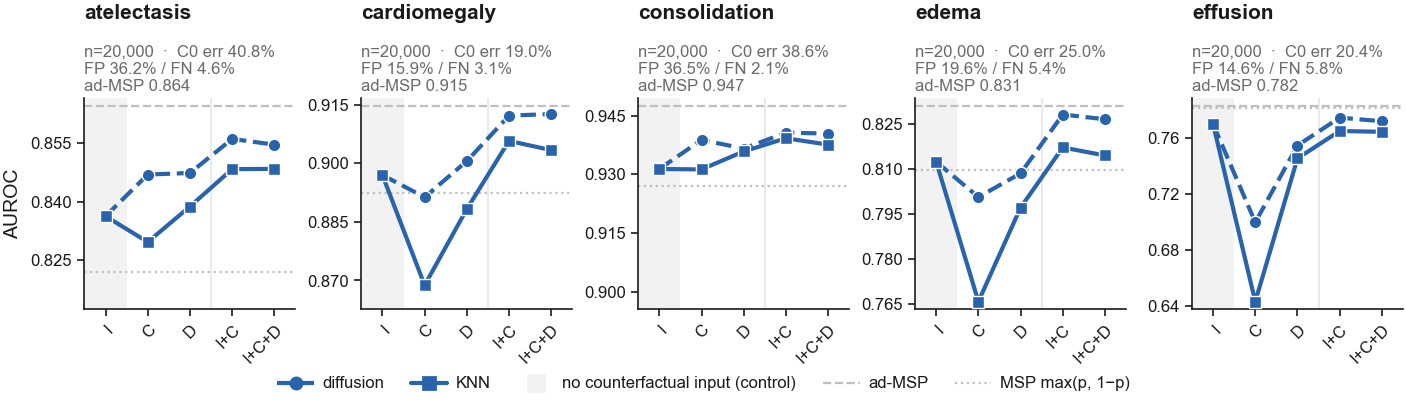

In [5]:
save_fig(arm_compare(CONFIG_ORDER, kind="attr", groups=CONFIG_GROUPS,
            shade=ATTR_NO_CF,
            title="Attribute configs (MLP): diffusion vs retrieved counterfactuals, "
                  "same 20k rows and folds"), "aim1b_attr_vs_knn");


## 1c. CNN variants

The image models on the same absolute axis, read the same way: what does each set of image
inputs know about C0's correctness. The rule separates the models that see a single image from
those that see the query/counterfactual pair, which is the comparison this figure exists to
make.

`xi` and `xi_sal` never open a counterfactual, so their K lines coincide by construction -
that is a check on the pipeline, not a finding. They are the shaded band.

Only models with a complete `fold_aucs.csv` appear, so this renders correctly mid-run.

/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


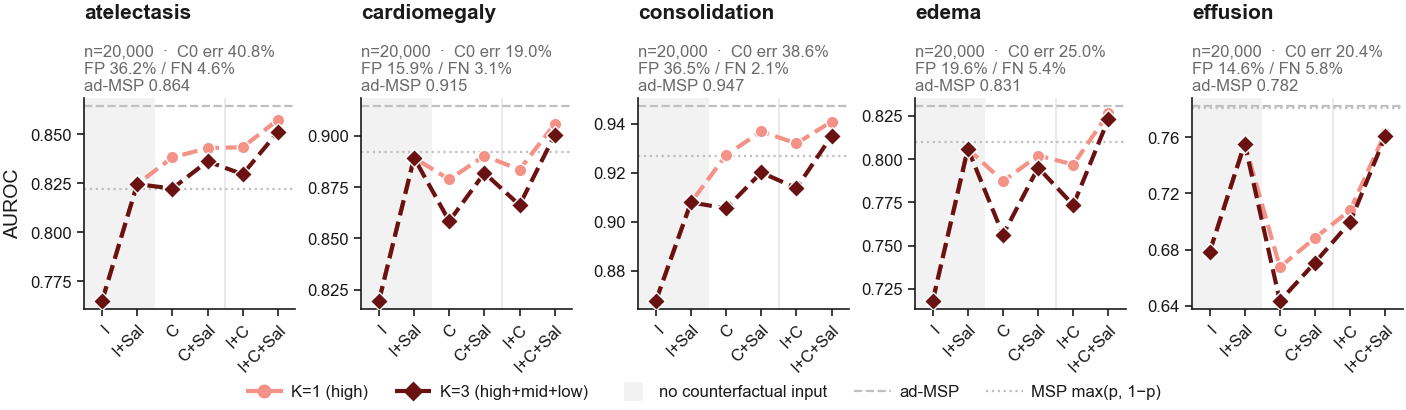

In [6]:
def cnn_ladder(diseases=DISEASES, ks=None, win=0.05, ncols=None, panel=LADDER_PANEL):
    """Same figure for the image models."""
    ks, panels = ks or K_VALUES, []
    for d in diseases:
        # The C0 probability column is what MSP needs and it does not depend on K, so one
        # attribute frame (at FINAL["k"]) supplies it for every K series.
        att = load_attributes(d, FINAL["k"])
        if att is None: continue
        series, ref, base = {}, None, None
        for k in ks:
            cnn = load_cnn(d, k)
            if cnn is None: continue
            cols = [f"cnn_{key}" for key in CNN_KEYS
                    if f"cnn_{key}" in cnn.columns and cnn[f"cnn_{key}"].notna().all()]
            if not cols: continue
            # MSP must be scored on the SAME rows as the CNN, so merge and take one frame.
            m = cnn.merge(att[["path", f"{d}_prob"]], on="path", how="inner")
            series[k] = {c.replace("cnn_", ""): per_fold_auc(m, c) for c in cols}
            if ref is None:
                ref, base = m, msp_bases(m, d)
        if series:
            panels.append((d, ref, base, series))

    if not panels:
        print("no finished CNN models yet for", SOURCE); return
    # dual_sal_scalars is left out of the sweep, as in C2_evaluation.ipynb: it is not on the
    # xi -> dual -> dual_sal ladder, and one more near-identical line only crowds the panel.
    rows = [key for key in CNN_KEYS if key != "dual_sal_scalars"
            and any(key in s[k] for _, _, _, s in panels for k in s)]

    colors = k_colors("cnn", ks)
    fig, axes = row_grid(len(panels)) if ncols is None else _grid(len(panels), ncols, panel)
    for ax, (d, ref, base, series) in zip(axes, panels):
        # Shade the no-counterfactual models, NOT CNN_GROUPS[0] -- that group also holds
        # cf and cf_sal, which are counterfactual models.
        line_panel(ax, rows, series, CNN_GROUPS, auroc_ylim(series, base, win),
                   base=base, colors=colors, shade=CNN_NO_CF, labels=CNN_LABELS,
                   ls=DIFF_LS)
        _panel_title(ax, d, ref, base)
        ax.set_ylabel("AUROC")
    drawn = sorted({k for _, _, _, s in panels for k in s})
    if ncols is None:
        row_legend(fig, axes, k_legend(drawn, colors, ls=DIFF_LS))
    else:
        corner_legend(fig, len(panels), ncols, k_legend(drawn, colors, ls=DIFF_LS))
    return fig

save_fig(cnn_ladder(), "aim1c_cnn_k_sweep");

## 1d. CNN variants: diffusion vs KNN

The same paired figure for the image models.

**`xi` and `xi_sal` are the control here.** They never open a counterfactual - they see the
query image and, for `xi_sal`, its Grad-CAM - so the two arms are training the identical model
on the identical rows. Their two arms must agree up to the run-to-run noise of a DenseNet trained
from a fixed seed. They are the shaded band, and they are the first thing to look at: if the two
lines do not meet there, the difference further right is not about counterfactuals.

`cf` and `cf_sal` are the other extreme - they see *only* the counterfactual - so they are
where the two arms differ most by construction.

/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


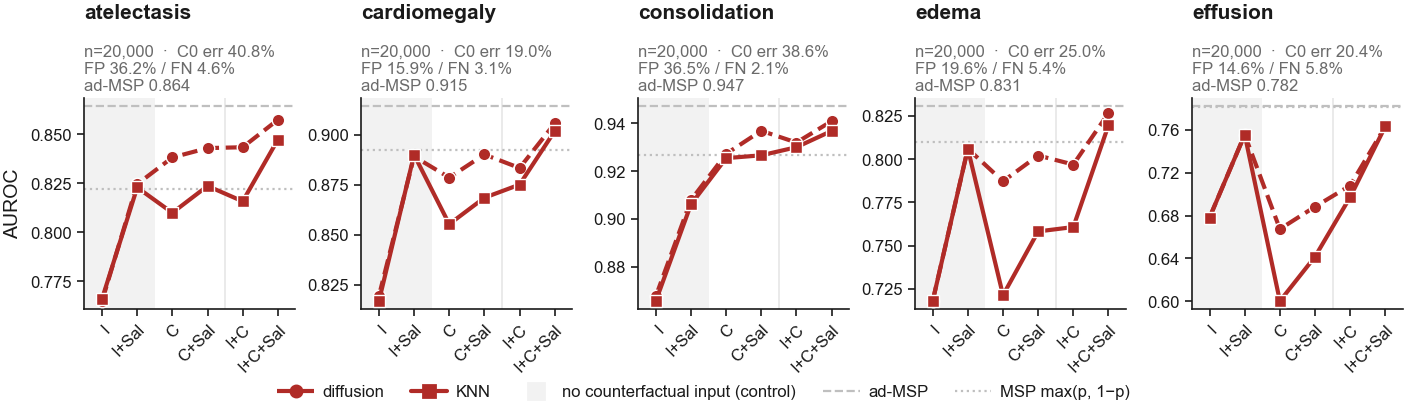

In [7]:
save_fig(arm_compare([k for k in CNN_KEYS if k != "dual_sal_scalars"], kind="cnn", groups=CNN_GROUPS,
            shade=CNN_NO_CF, labels=CNN_LABELS,
            title="CNN variants: diffusion vs retrieved counterfactuals, "
                  "same 20k rows and folds"), "aim1d_cnn_vs_knn");


## 1e. Trajectory models

Models that never look at the counterfactual image, nor at C0's probability on the query (**prob-free**,
no MSP skip): they only read **C0's probability along the diffusion trajectory** (recorded every 5
denoising steps, 30 values per level). Written by `c2_train_trajectory.py`; exploration in
`trajectory_fingerprint.ipynb`.

**Points: one model each, with its 95% bootstrap interval** (patient-level, seed 0, 5,000 draws, as in
`bootstrapping_diffusion.ipynb`; replayed here and cached as `bootstrap_diffusion_trajectory_K1_replicates.csv`).
The x order is fixed in every panel and the points are not joined: the blocks are separate models, not a
sequence. First the MLP on blocks of the trajectory fingerprint (32 hand-made features), each block
alone, then all together:

| block | features | what it describes |
|---|---|---|
| `LEVEL` | start / end value, net change, fitted level, threshold crossings | where the trajectory sits and whether it flips |
| `MONO` | monotone ratio, backtracking, reversals, rank correlation with time | how steadily it moves one way |
| `SHAPE` | slope, curvature, S-shape and misfit of a cubic fit | the shape of the curve |
| `DYN` | path length, velocity and acceleration summaries | how much and how fast it moves |

**Tinted band: sequence models on the whole trajectory** - a 1D CNN (feature map flattened, so it
knows *when* things happen) and a bidirectional GRU. Both read the logit of the probability of the class
the counterfactual is heading to, plus its step-to-step change.

Everything is trained the same way as the attribute MLP of `c2_block_ablation.ipynb`: class-balanced BCE
and early stopping on the AUC of a patient-grouped validation split. As in the attribute arm, each model is
trained on the `high` level only and applied per level; K averages the per-level scores.

**Plotted at K=1** (the `high`, most extreme counterfactual). K=3 is computed and saved too
(`TRAJ_K = 3` to draw it; expected to be weaker: the models never saw `mid`/`low` trajectories in
training). The sixth panel averages the five diseases, its interval averaged inside each replicate.

/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


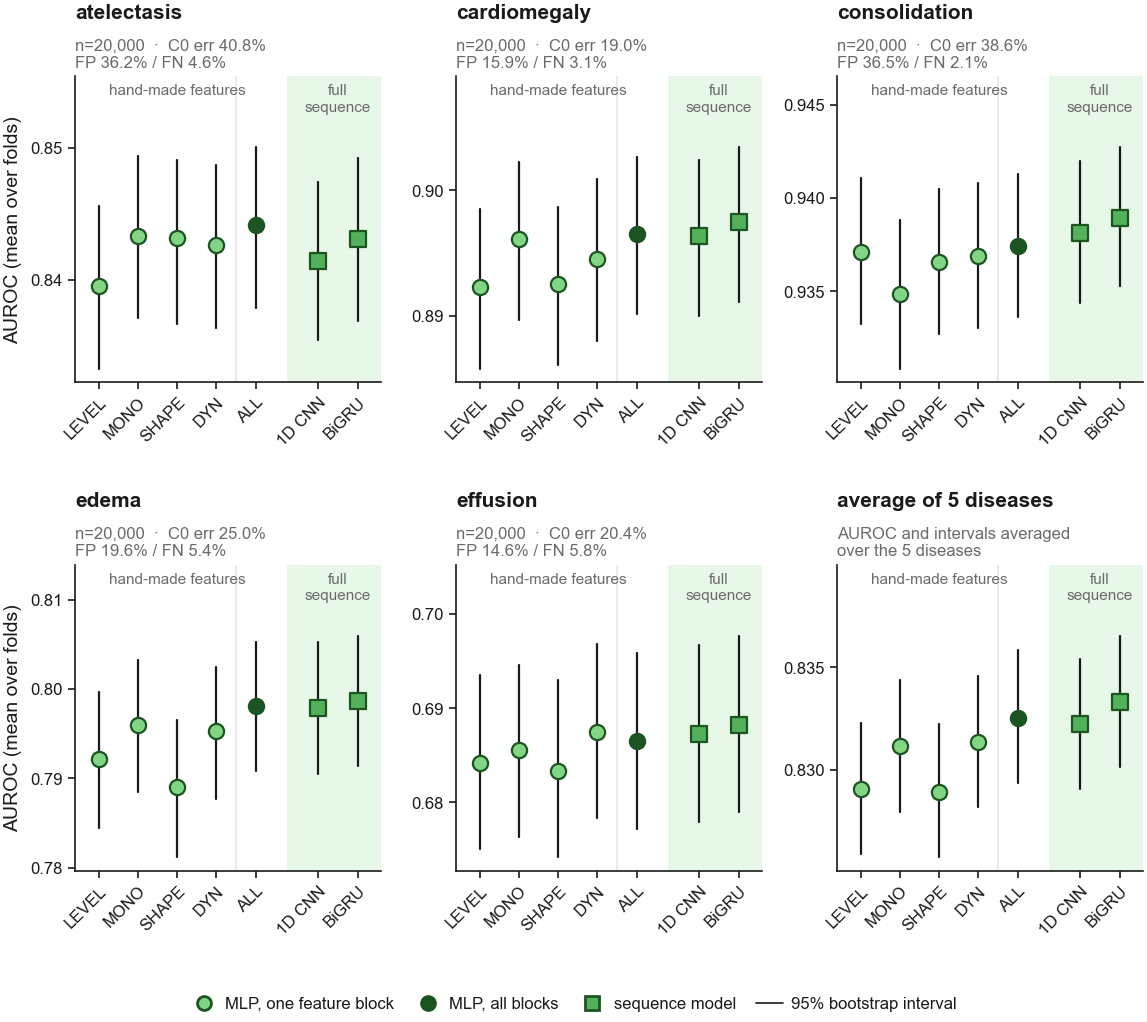

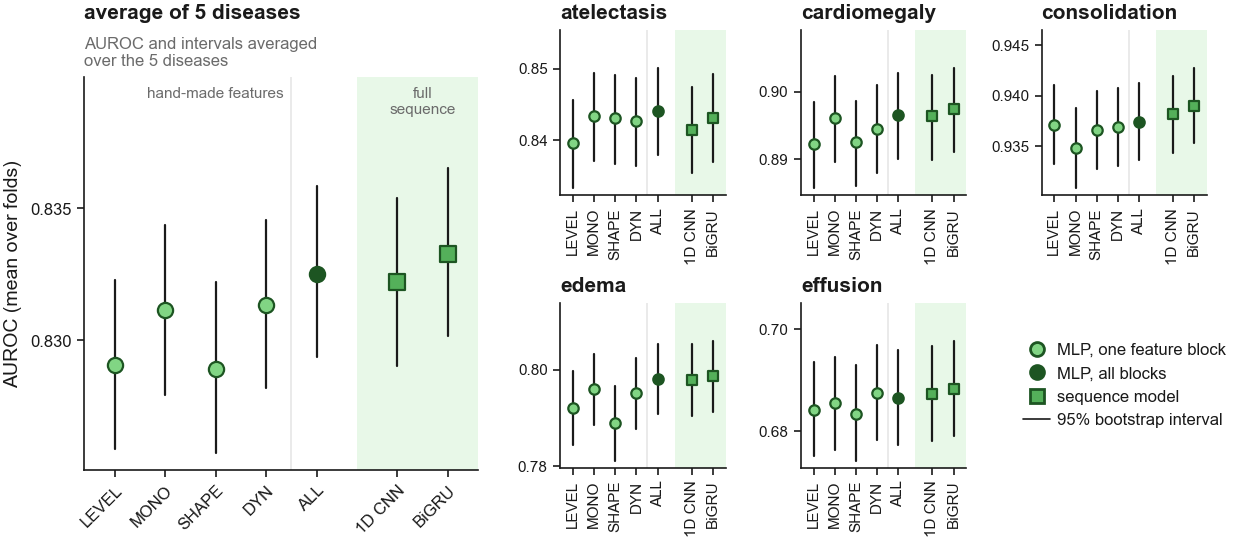

In [8]:
TRAJ_BLOCKS = ["LEVEL", "MONO", "SHAPE", "DYN", "ALL"]       # MLP on fingerprint blocks
TRAJ_SEQ    = {"CNN": "1D CNN", "RNN": "BiGRU"}               # sequence models, whole trajectory
TRAJ_K      = 1                                                # K=1: the high (extreme) CF only

# One fixed x order in every panel -- the blocks are separate models, not a sequence, so
# they are neither sorted by value nor joined by a line. The sequence models sit after a
# gap, on a tinted band: "hand-made features" | "full sequence".
TRAJ_X      = {**{b: i for i, b in enumerate(TRAJ_BLOCKS)},
               **{m: len(TRAJ_BLOCKS) + 0.6 + j for j, m in enumerate(TRAJ_SEQ)}}
TRAJ_COLS   = {**{b: f"MLP_{b}_prob" for b in TRAJ_BLOCKS},
               **{m: f"{m}_TRAJ_prob" for m in TRAJ_SEQ}}
TRAJ_LABELS = {**{b: b for b in TRAJ_BLOCKS}, **TRAJ_SEQ}
# Single blocks light, ALL dark; the sequence models full green with a square marker.
TRAJ_STYLE  = {**{b: (RAMP["traj"][0], "o") for b in TRAJ_BLOCKS[:-1]},
               "ALL": (RAMP["traj"][2], "o"),
               **{m: (FAMILY["traj"], "s") for m in TRAJ_SEQ}}

# Same patient bootstrap as bootstrapping_diffusion.ipynb (seed, n_boot, mean-fold AUROC),
# replayed here because the main export does not score the trajectory models. Cached: the
# replay takes a minute or two.
TRAJ_BOOT_FILE = os.path.join(C2, f"bootstrap_diffusion_trajectory_K{TRAJ_K}_replicates.csv")
TRAJ_N_BOOT, TRAJ_SEED = 5000, 0


def traj_dir(d, k=None, source=None):
    return os.path.join(C2, d, source or SOURCE, f"cf_{k or FINAL['k']}", "trajectory")


def load_trajectory(disease, k=None, n_folds=5, source=None):
    """Pooled OOF predictions of c2_train_trajectory.py for one K, or None if not finished."""
    parts = []
    for i in range(n_folds):
        p = os.path.join(traj_dir(disease, k, source), f"fold_{i}_predictions.csv")
        if not os.path.exists(p):
            return None
        f = pd.read_csv(p); f["fold"] = i
        parts.append(f)
    return pd.concat(parts, ignore_index=True)


def traj_bootstrap(frames, k=TRAJ_K, n_boot=TRAJ_N_BOOT, seed=TRAJ_SEED, rerun=False):
    """Replicate x (disease, model) mean-fold AUROC of every trajectory model. Patients are
    drawn once per replicate over all diseases, as in the main bootstrap."""
    if os.path.exists(TRAJ_BOOT_FILE) and not rerun:
        reps = pd.read_csv(TRAJ_BOOT_FILE, index_col="replicate")
        reps.columns = pd.MultiIndex.from_tuples([tuple(c.split("|", 1)) for c in reps.columns])
        if set(reps.columns.get_level_values(0)) == set(frames):
            return reps
    import c2_boot_extra as BX
    tables = {d: f[["correct", "patient_id", "fold"] + [TRAJ_COLS[m] for m in TRAJ_COLS]]
              for d, f in frames.items()}
    print(f"trajectory bootstrap: {n_boot} replicates ...")
    rng      = np.random.default_rng(seed)
    patients = pd.Index(sorted(set().union(*(set(t.patient_id) for t in tables.values()))))
    codes    = {d: patients.get_indexer(t.patient_id) for d, t in tables.items()}
    auc      = {d: BX.FoldMean(t, list(TRAJ_COLS.values()), BX.WeightedAUC)
                for d, t in tables.items()}
    name     = {c: m for m, c in TRAJ_COLS.items()}
    rows     = []
    for b in range(n_boot):
        w = np.bincount(rng.integers(0, len(patients), len(patients)),
                        minlength=len(patients)).astype(float)
        rows.append({(d, name[c]): v for d, s in auc.items()
                     for c, v in zip(s.cols, s(w[codes[d]]))})
    reps = pd.DataFrame(rows); reps.index.name = "replicate"
    reps.columns = pd.MultiIndex.from_tuples(reps.columns)
    out = reps.copy(); out.columns = [f"{d}|{m}" for d, m in reps.columns]
    out.to_csv(TRAJ_BOOT_FILE)
    return reps


def traj_interval(reps, disease, model, level=0.95):
    """Percentile interval; for AVERAGE the diseases are averaged inside each replicate."""
    ds = DISEASES if disease == "AVERAGE" else [disease]
    v  = np.mean([reps[(d, model)].to_numpy() for d in ds], axis=0)
    a  = (1 - level) / 2 * 100
    return np.percentile(v, [a, 100 - a])


def traj_round_ticks(ax, nbins=4):
    """3-4 y-ticks on a round step, as in the points figures of 1f / 1g."""
    from matplotlib.ticker import MaxNLocator, FormatStrFormatter
    loc = MaxNLocator(nbins=nbins, steps=[1, 2, 5, 10])
    ax.yaxis.set_major_locator(loc)
    t = loc.tick_values(*ax.get_ylim())
    step = (t[1] - t[0]) if len(t) > 1 else 0.01
    ax.yaxis.set_major_formatter(FormatStrFormatter(f"%.{max(2, int(np.ceil(-np.log10(step) - 1e-9)))}f"))


def traj_points_panel(ax, h, ci, compact=False):
    """One panel: a point + 95% whisker per model. No MSP (Aim 1): the y range is fitted to the
    intervals. `compact` is a small panel of the key figure: smaller points and text."""
    lo, hi = ci[:, 0].min(), ci[:, 1].max()
    span   = max(hi - lo, 0.01)
    # Headroom above the top value for the two group labels.
    ax.set_ylim(lo - span * 0.06, hi + span * 0.32)
    xs  = [TRAJ_X[m] for m in TRAJ_COLS]
    x0  = len(TRAJ_BLOCKS) - 0.5 + 0.3                     # middle of the gap
    ax.axvspan(x0, xs[-1] + 0.6, color=TINT["traj"], alpha=0.6, lw=0, zorder=0)
    ax.axvline(len(TRAJ_BLOCKS) - 1.5, color=HAIR, lw=LW["axis"], zorder=0)  # blocks | ALL

    for (m, v), (l, u), x in zip(h.items(), ci, xs):
        c, mk = TRAJ_STYLE[m]
        ax.plot([x, x], [l, u], color=INK, lw=LW["ref"], zorder=3)
        ax.scatter([x], [v], s=14 if compact else 30, marker=mk, c=[c], edgecolors=[RAMP["traj"][2]],
                   linewidths=0.8, zorder=4)

    ax.set_xticks(xs)
    ax.set_xticklabels([TRAJ_LABELS[m] for m in TRAJ_COLS],
                       fontsize=FS["tiny"] if compact else FS["small"],
                       rotation=90 if compact else 45,       # 45 deg collides at small size
                       ha="right", va="center" if compact else "top", rotation_mode="anchor")
    ax.set_xlim(-0.6, xs[-1] + 0.6)
    traj_round_ticks(ax, nbins=3 if compact else 4)
    if compact:
        ax.tick_params(axis="y", labelsize=FS["tiny"])
    ax.set_box_aspect(1)


def traj_specs(diseases=DISEASES, k=TRAJ_K, rerun=False):
    """(frames, replicates, AUROCs, panels), or None before any run has finished.
    The AVERAGE panel only once every disease has."""
    frames = {d: f for d in diseases if (f := load_trajectory(d, k)) is not None}
    if not frames:
        return None
    reps   = traj_bootstrap(frames, k, rerun=rerun)
    ds     = list(frames)
    vals   = {d: {m: per_fold_auc(f, c) for m, c in TRAJ_COLS.items()} for d, f in frames.items()}
    vals["AVERAGE"]  = {m: float(np.mean([vals[d][m] for d in ds])) for m in TRAJ_COLS}
    return frames, reps, vals, ds + (["AVERAGE"] if len(ds) == len(DISEASES) else [])


def traj_draw(frames, reps, vals):
    """draw(ax, panel, compact) for one trajectory panel, for the grid and key_figure alike.
    A small panel keeps only the disease name as its title, and no group labels."""
    ds = list(frames)

    def draw(ax, d, compact=False):
        ci = np.array([traj_interval(reps, d, m) for m in TRAJ_COLS])
        traj_points_panel(ax, vals[d], ci, compact)
        if compact:
            ax.set_title(f"average of {len(ds)} diseases" if d == "AVERAGE" else d)
            return
        if d == "AVERAGE":
            # Same two-line subtitle height as the disease panels, so the rows line up.
            note = f"AUROC and intervals averaged\nover the {len(ds)} diseases"
            ax.set_title(f"average of {len(ds)} diseases", pad=13 + 1.3 * FS["small"])
            ax.text(0.0, 1.02, note, transform=ax.transAxes, ha="left", va="bottom",
                    fontsize=FS["small"], color=MUTED)
        else:
            _panel_title(ax, d, frames[d])          # n / C0 err / FP-FN
        # Group labels just above the axes top, under the subtitle.
        ax.text((len(TRAJ_BLOCKS) - 1) / 2, 0.975, "hand-made features", ha="center", va="top",
                fontsize=FS["tiny"], color=MUTED, transform=ax.get_xaxis_transform())
        ax.text(np.mean([TRAJ_X[m] for m in TRAJ_SEQ]), 0.975, "full\nsequence", ha="center",
                va="top", fontsize=FS["tiny"], color=MUTED, transform=ax.get_xaxis_transform())
    return draw


def traj_legend():
    pt = lambda c, mk, lab: Line2D([], [], ls="none", marker=mk, markersize=5, color=c,
                                   markeredgecolor=RAMP["traj"][2], label=lab)
    return [pt(RAMP["traj"][0], "o", "MLP, one feature block"),
            pt(RAMP["traj"][2], "o", "MLP, all blocks"),
            pt(FAMILY["traj"], "s", "sequence model"),
            Line2D([], [], color=INK, lw=LW["axis"], label="95% bootstrap interval")]


def traj_points(diseases=DISEASES, k=TRAJ_K, ncols=3, panel=LADDER_PANEL, rerun=False):
    t = traj_specs(diseases, k, rerun)
    if t is None:
        print("no trajectory predictions yet - run jobs/c2_trajectory.sh"); return
    panels = t[3]
    draw   = traj_draw(*t[:3])
    fig, axes = _grid(len(panels), ncols, panel)
    for ax, d in zip(axes, panels):
        draw(ax, d)
    for ax in axes[::ncols]:
        ax.set_ylabel("AUROC (mean over folds)")
    fig.legend(handles=traj_legend(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.01))
    square_tight_layout(fig, rect=(0, 0.04, 1, 1))
    return fig


def traj_points_key(diseases=DISEASES, k=TRAJ_K):
    t = traj_specs(diseases, k)
    if t is None or "AVERAGE" not in t[3]:
        print("the trajectory key figure needs every disease's trajectory run"); return
    return key_figure(t[3], traj_draw(*t[:3]), traj_legend())


save_fig(traj_points(), "aim1e_trajectory");
save_key_fig(traj_points_key(), "aim1e_trajectory");


## Bootstrap results

The statistics on the bar figures and in Aim 2 -- whiskers, brackets, stars -- come from
`bootstrapping_diffusion.ipynb` (paired, patient-level, mean-fold AUROC). Its export has the
same shape, comparison names and Holm families as the KNN bootstrap, `AVERAGE` rows included,
so this cell is the KNN notebook's loader pointed at the diffusion files. Run that notebook
first; this cell stops if its files are missing or were written for another final system.


In [9]:
import json

BOOT_FILES = {n: os.path.join(C2, f"bootstrap_diffusion_{n}")
              for n in ("deltas.csv", "replicates.csv", "meta.json")}


def load_bootstrap():
    missing = [p for p in BOOT_FILES.values() if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError("bootstrap results not found -- run "
                                "final_experiment/bootstrapping_diffusion.ipynb first:\n  "
                                + "\n  ".join(missing))
    deltas = pd.read_csv(BOOT_FILES["deltas.csv"])
    reps   = pd.read_csv(BOOT_FILES["replicates.csv"], index_col="replicate")
    reps.columns = pd.MultiIndex.from_tuples([tuple(c.split("|", 1)) for c in reps.columns],
                                             names=["disease", "model"])
    meta   = json.load(open(BOOT_FILES["meta.json"]))
    return deltas, reps, meta


BOOT_DELTAS, BOOT_REPS, BOOT_META = load_bootstrap()

# The bootstrap must have scored the same models this notebook plots.
assert BOOT_META["model"] == "MLP", BOOT_META["model"]
assert BOOT_META["diseases"] == DISEASES, (BOOT_META["diseases"], DISEASES)
assert BOOT_META["families"] == {"I": ["I"], "I+C": ["I+C"], "I+C+D": ["I+C+D"]}, \
    BOOT_META["families"]
assert BOOT_META.get("cnn_families") == {"xi": ["xi"], "dual": ["dual"], "dual_sal": ["dual_sal"]}, \
    "bootstrap predates the xi -> dual -> dual_sal CNN ladder -- rerun bootstrapping_diffusion.ipynb"
assert BOOT_META.get("final") == FINAL, \
    f"bootstrap final system {BOOT_META.get('final')} != {FINAL} -- rerun bootstrapping_diffusion.ipynb"
assert BOOT_META.get("msp_variant", "standard") == MSP_VARIANT, \
    (f"bootstrap tested MSP variant {BOOT_META.get('msp_variant', 'standard')!r}, this notebook "
     f"draws {MSP_VARIANT!r} -- rerun bootstrapping_diffusion.ipynb with the same MSP_VARIANT")
assert "AVERAGE" in set(BOOT_DELTAS.disease), \
    "bootstrap export has no AVERAGE rows -- rerun bootstrapping_diffusion.ipynb"


STAR_LEVELS = [(t, s) for t, s in [(0.001, "***"), (0.01, "**"), (BOOT_META["alpha"], "*")]
               if t > 1 / BOOT_META["n_boot"]]
STARS_KEY   = ", ".join(f"{s} p < {t:g}" for t, s in STAR_LEVELS) + ", n.s. not significant"


def stars(p):
    return next((s for t, s in STAR_LEVELS if p < t), "n.s.")


def boot_row(comparison, disease):
    r = BOOT_DELTAS[(BOOT_DELTAS.comparison == comparison) & (BOOT_DELTAS.disease == disease)]
    if len(r) != 1:
        raise KeyError(f"no bootstrap row for {comparison!r} / {disease!r}")
    return r.iloc[0]


def boot_interval(disease, models, level=0.95):
    """Percentile interval of the mean-fold AUROC averaged over `models`. For "AVERAGE" the
    diseases are averaged inside each replicate, so the interval keeps the pairing."""
    ds = DISEASES if disease == "AVERAGE" else [disease]
    v  = np.mean([BOOT_REPS[d][list(models)].mean(axis=1).to_numpy() for d in ds], axis=0)
    a  = (1 - level) / 2 * 100
    return np.percentile(v, [a, 100 - a])


print(f"bootstrap: {BOOT_META['n_boot']} replicates, written {BOOT_META['created']}")


bootstrap: 5000 replicates, written 2026-10-29T16:09:18


## 1f. Adding the counterfactual: I vs I+C vs I+C+D

The diffusion version of 1d in `C2_evaluation.ipynb`: the test of the model 1a built. Each bar
is one attribute config's mean-fold AUROC at `FINAL["k"]` = 1 (the `high` level), the K chosen
in 1a: the query alone (I), plus the counterfactual (I+C), plus the explicit deltas (I+C+D).

* **Whiskers** -- 95% bootstrap interval of that config's AUROC.
* **Brackets** -- paired bootstrap test of the difference, from `bootstrapping_diffusion.ipynb`,
  Holm-adjusted as in the KNN arm: across the five diseases for a disease panel, across the
  nine claims for the average panel.

**Whiskers are not the test.** Both configs are scored on the same patients, so their
difference is far less noisy than either bar. Read significance off the brackets only.

The axis starts at 0.5, chance-level AUROC, and is shared by every panel.

**No MSP lines.** This is Aim 1: each rung is judged against the input-only rung (I),
not against MSP. MSP enters in Aim 2.

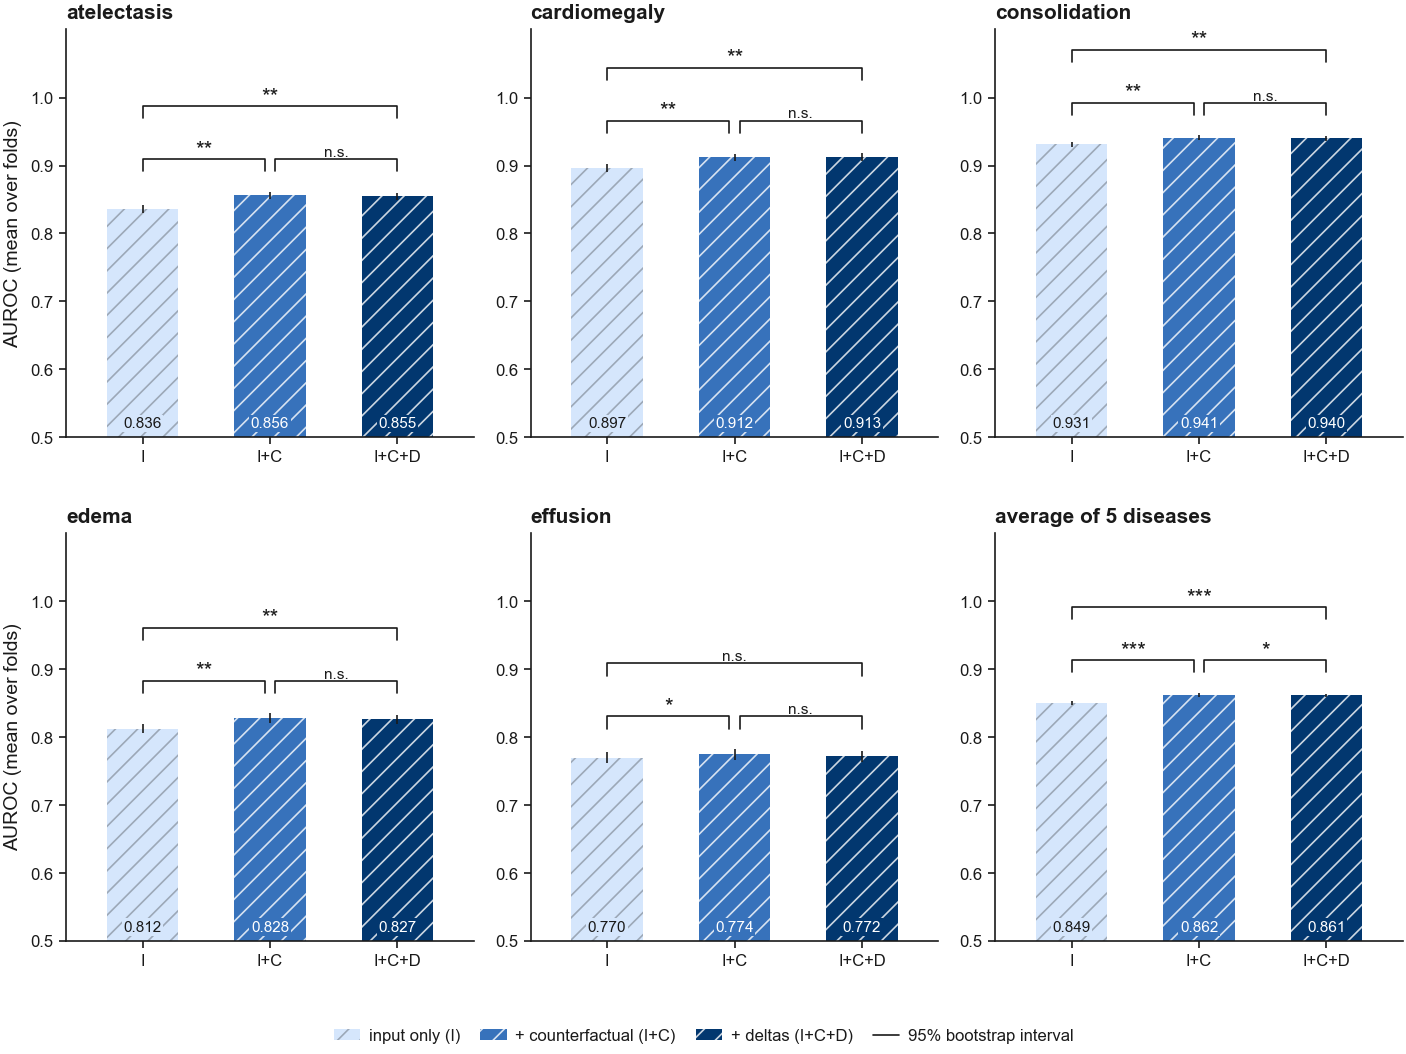

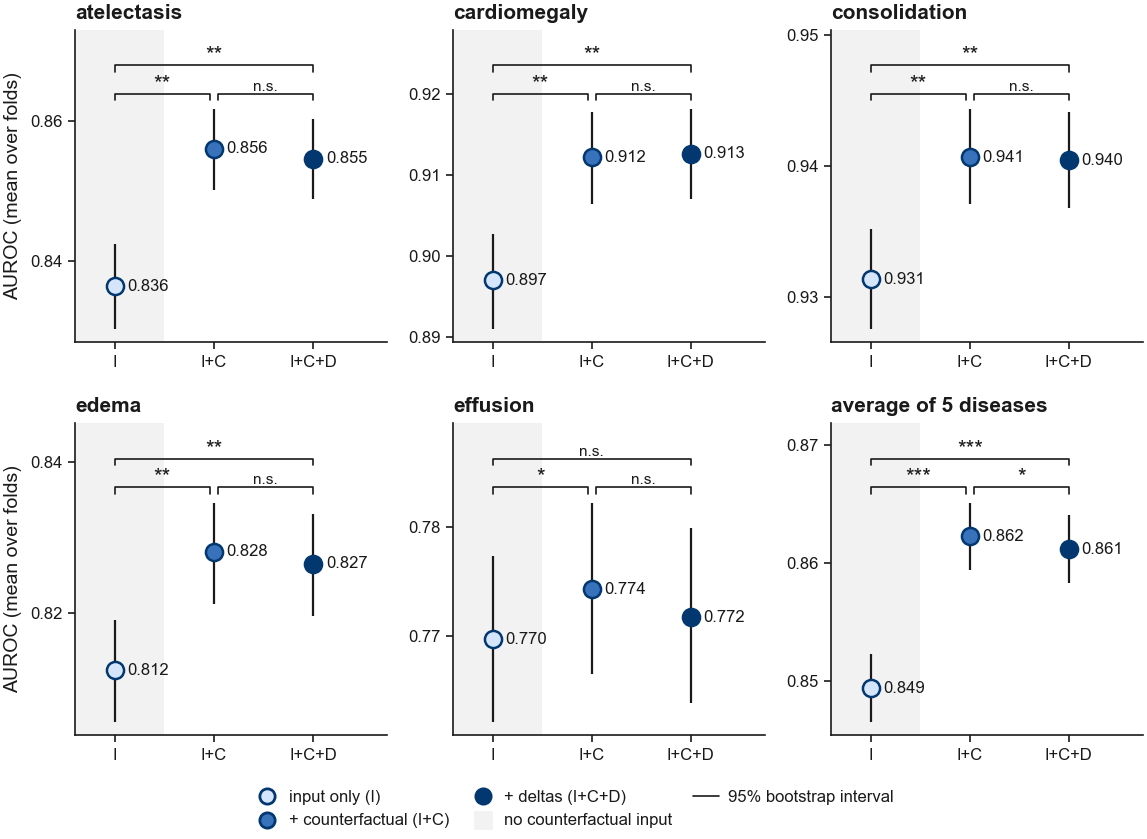

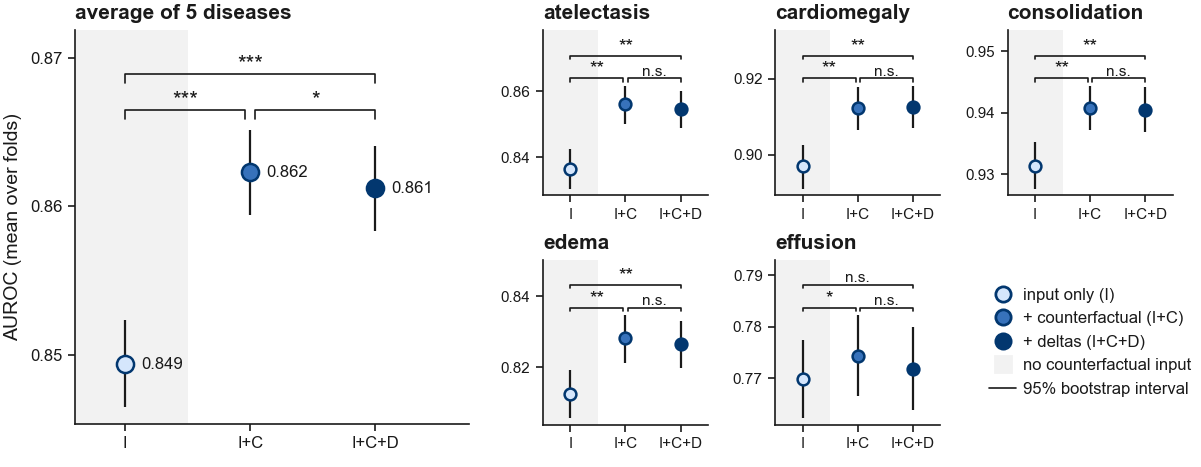

In [10]:
FAMILY_NAMES = list(BOOT_META["families"])                       # ["I", "I+C", "I+C+D"]
# (bracket x from, x to, comparison in bootstrapping_diffusion.ipynb, bracket level). The two
# adjacent brackets both end on I+C, so they stop just short of it instead of touching.
FAMILY_CMP = [(0.00, 0.96, "I+C - I",     0),
              (1.04, 2.00, "I+C+D - I+C", 0),
              (0.00, 2.00, "I+C+D - I",   1)]


def family_scores(disease):
    """Family-average mean-fold AUROC at FINAL["k"], and both MSPs, for one disease."""
    df   = load_attributes(disease, FINAL["k"])
    aucs = {c: per_fold_auc(df, col) for c, col in config_cols(df).items()}
    return ({f: float(np.mean([aucs[c] for c in cs])) for f, cs in BOOT_META["families"].items()},
            msp_bases(df, disease))


def bracket(ax, x1, x2, y, h, text, small=False):
    """`small` sets the stars at body size, for the compact side panels."""
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color=INK, lw=LW["axis"], zorder=4)
    ax.text((x1 + x2) / 2, y + h, text, ha="center", va="bottom", color=INK,
            fontsize=FS["tiny"] if text == "n.s." else FS["base"] if small else FS["head"],
            zorder=4)


def family_bars_draw(ax, h, ci, colors):
    """Bars from 0.5 (chance), thin ink whiskers, the value inside the bar foot."""
    x = np.arange(len(h))
    for xi, v, col in zip(x, h, colors):
        diff_bar(ax, xi, v - 0.5, col, bottom=0.5, width=0.56, zorder=2)
    ax.errorbar(x, h, yerr=[h - ci[:, 0], ci[:, 1] - h], fmt="none", ecolor=INK,
                elinewidth=LW["axis"], zorder=3)
    for xi, v, col in zip(x, h, colors):
        # Backed by the bar colour, so the hatch does not run through the digits.
        ax.text(xi, 0.51, f"{v:.3f}", ha="center", va="bottom", fontsize=FS["tiny"],
                color=INK if col in TINT.values() else "white", zorder=3,
                bbox=dict(fc=col, ec="none", pad=0.6))
    return x


# Lightness = how much counterfactual the config sees: I none (tint), I+C, I+C+D darkest.
FAMILY_COLORS = [TINT["attr"], RAMP["attr"][1], RAMP["attr"][2]]


def bar_panel(ax, disease, h, ci, colors, names, cmps, base, ymax):
    family_bars_draw(ax, h, ci, colors)
    if base:                        # Aim 1 ladders pass None: no MSP
        draw_msp(ax, base)
    # Brackets stack above the tallest whisker in the figure, the same height in every panel.
    span, top = ymax - 0.5, ci[:, 1].max()
    for x1, x2, name, level in cmps:
        bracket(ax, x1, x2, top + span * (0.05 + 0.13 * level), span * 0.03,
                stars(boot_row(name, disease).p_adj))
    ax.set_xticks(np.arange(len(names)), names)
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.set_title(f"average of {len(DISEASES)} diseases" if disease == "AVERAGE" else disease)
    ax.set_box_aspect(1)            # square plotting area, like every other panel


def family_bars(diseases=DISEASES, ncols=3, panel=(FULL / 3, 68 * MM)):
    k      = FINAL["k"]
    cols   = {f: [f"{c}@K{k}" for c in cs] for f, cs in BOOT_META["families"].items()}
    scores = {d: family_scores(d) for d in diseases}
    scores["AVERAGE"] = ({f: np.mean([scores[d][0][f] for d in diseases]) for f in FAMILY_NAMES},
                         mean_bases([scores[d][1] for d in diseases]))
    panels = list(diseases) + ["AVERAGE"]

    # One y scale for all panels: 0.5 up to room for two bracket levels above the tallest whisker.
    top  = max(boot_interval(d, cs)[1] for d in panels for cs in cols.values())
    ymax = 0.5 + (top - 0.5) / 0.74

    fig, axes = _grid(len(panels), ncols, panel=panel)
    for ax, d in zip(axes, panels):
        fam, base = scores[d]
        h  = np.array([fam[f] for f in FAMILY_NAMES])
        ci = np.array([boot_interval(d, cols[f]) for f in FAMILY_NAMES])
        bar_panel(ax, d, h, ci, FAMILY_COLORS, FAMILY_NAMES, FAMILY_CMP, None, ymax)
        ax.set_ylim(0.5, ymax)
        ax.set_yticks(np.arange(0.5, 1.001, 0.1))    # the space above 1 is for brackets only
    for ax in axes[::ncols]:
        ax.set_ylabel("AUROC (mean over folds)")

    fig.legend(handles=[diff_patch(TINT["attr"], "input only (I)"),
                        diff_patch(RAMP["attr"][1], "+ counterfactual (I+C)"),
                        diff_patch(RAMP["attr"][2], "+ deltas (I+C+D)"),
                        Line2D([], [], color=INK, lw=LW["axis"], label="95% bootstrap interval")],
               loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.03, 1, 0.99))
    return fig


save_fig(family_bars(), "aim1f_attr_blocks_bars");


# ── Points + 95% bootstrap whiskers: the same comparison without bars ──
# A point carries its value by position, not length, so the axis need not start at 0.5 and
# each panel zooms to its own intervals -- the thousandths between rungs become visible.
# Panels are therefore NOT on a shared y scale: compare models within a panel, not heights
# across panels. The bar version is still saved alongside.
from matplotlib.ticker import MaxNLocator, FormatStrFormatter


def pt_handle(face, edge, label):
    """Legend entry for one point style."""
    return Line2D([], [], ls="none", marker="o", markersize=5.5, color=face,
                  markeredgecolor=edge, label=label)


def round_ticks(ax, nbins=4):
    """3-4 y-ticks on a round step (1, 2 or 5 x 10^n), labelled with just enough decimals --
    every panel has its own range, so the ticks have to be easy to read on their own."""
    loc = MaxNLocator(nbins=nbins, steps=[1, 2, 5, 10])
    ax.yaxis.set_major_locator(loc)
    t = loc.tick_values(*ax.get_ylim())
    step = (t[1] - t[0]) if len(t) > 1 else 0.01
    ax.yaxis.set_major_formatter(FormatStrFormatter(f"%.{max(2, int(np.ceil(-np.log10(step) - 1e-9)))}f"))


# Points panels are smaller than the bar panels: with only a few points each, a large
# panel is mostly white space. The fonts stay at print size, so a smaller panel is what
# makes the points and values fill it. Square, like every other panel.
POINTS_PANEL  = (50 * MM, 54 * MM)    # one grid cell; 3 columns -> 150 mm wide
POINTS_ASPECT = 1                     # plot-area height / width

# Very transparent family tints behind a panel that mixes attribute and CNN models.
FAMILY_BAND_ALPHA = 0.22


def family_bands(ax, bands):
    """`bands` is [(x from, x to, family)], drawn behind everything."""
    for x0, x1, fam in bands:
        ax.axvspan(x0, x1, color=TINT[fam], alpha=FAMILY_BAND_ALPHA, lw=0, zorder=0)


def points_panel(ax, disease, h, ci, colors, edges, names, cmps, base, hollow=(), bands=(),
                 shade=(), values_above=False, row_fn=None, fmt="{:.3f}", compact=False,
                 small_ticks=None):
    """One panel: a point per model with its whisker and value, the MSPs, and the brackets.
    `cmps` is (x from, x to, bootstrap comparison, bracket level); `hollow` lists the indices
    drawn as open points; `bands` tints the background by model family; `shade` lists the
    indices of the models with no counterfactual input, banded grey as in the K ladders.
    `values_above` writes each value above its whisker instead of beside the point -- for
    panels with too many points for the value to fit before the next one. `row_fn(name,
    disease)` returns a bracket's bootstrap row; boot_row unless the test lives elsewhere.
    `fmt` formats the printed values (E-AURC needs four decimals). `base` None draws no MSP:
    the Aim 1 ladders are judged against their own input-only rung, not MSP. `compact` is a
    small side panel of the key figure: no values, smaller points, fewer y-ticks, and only the
    adjusted MSP printed; `small_ticks` [(x, label)] replaces its tick labels when they would
    collide (one label per family, say)."""
    row_fn = row_fn or boot_row
    values_above = values_above and not compact
    x      = np.arange(len(h))
    lo, top = ci[:, 0].min(), ci[:, 1].max()
    span   = max(top - lo, 1e-4)
    levels = max((c[3] for c in cmps), default=-1) + 1
    # Values above the whiskers push the brackets up by one text line, and the taller y range
    # they need shrinks the gap between bracket levels, so the levels are spaced wider.
    lift   = 0.09 if values_above else 0.0
    step   = 0.16 if values_above else 0.13
    # A small panel squeezes the same star height into less span, so its levels sit further apart.
    step  += 0.09 if compact else 0.0
    # Tight: just enough room below for the MSP note and above for the bracket levels, so
    # the data fill the panel rather than its lower half.
    below  = (0.22 if compact else 0.16) if base else 0.06
    ax.set_ylim(lo - span * below, top + span * (0.10 + lift + step * levels))
    if compact:
        ax.set_xlim(-0.5, len(x) - 0.5)
    else:
        ax.set_xlim(-0.4, len(x) - 0.25)    # a little extra on the right for the values
    family_bands(ax, bands)
    for i in shade:
        ax.axvspan(i - 0.5, i + 0.5, color=SHADE, lw=0, zorder=0)

    ax.errorbar(x, h, yerr=[h - ci[:, 0], ci[:, 1] - h], fmt="none", ecolor=INK,
                elinewidth=LW["ref"], capsize=0, zorder=3)
    for i, (v, c, e) in enumerate(zip(h, colors, edges)):
        ax.scatter([i], [v], s=18 if compact else 38, c=["white" if i in hollow else c],
                   edgecolors=[e], linewidths=0.9, zorder=4)
        if compact:
            continue
        if values_above:
            # White backing: the reference lines often run through this height.
            ax.text(i, ci[i, 1] + span * 0.02, fmt.format(v), ha="center", va="bottom",
                    fontsize=FS["small"], color=INK, zorder=4,
                    bbox=dict(fc="white", ec="none", pad=0.4, alpha=0.85))
        else:
            ax.text(i + 0.13, v, fmt.format(v), ha="left", va="center", fontsize=FS["small"],
                    color=INK, zorder=4)

    # The MSPs usually sit well below the zoomed range: a line only when one falls inside
    # it, and always the values, so the reference is never lost.
    if base:
        y0, y1 = ax.get_ylim()
        for v, y in base.items():
            if y0 <= y <= y1:
                ax.axhline(y, color=GREY, ls=MSP_SHOWN[v][2], lw=LW["ref"], zorder=1)
        shown = {MSP_VARIANT: base[MSP_VARIANT]} if compact else base
        ax.text(0.02, 0.025, "  ".join(f"{MSP_SHOWN[v][1]} {fmt.format(y)}" for v, y in shown.items()),
                transform=ax.transAxes, ha="left", va="bottom",
                fontsize=FS["tiny"] if compact else FS["small"], color=MUTED)

    for x1, x2, name, level in cmps:
        bracket(ax, x1, x2, top + span * (0.04 + lift + step * level), span * 0.03,
                stars(row_fn(name, disease).p_adj), small=compact)

    round_ticks(ax, nbins=3 if compact else 4)
    if compact and small_ticks:
        ax.set_xticks(*zip(*small_ticks))
    else:
        ax.set_xticks(x, names)
    if compact:
        ax.tick_params(labelsize=FS["tiny"])
    ax.set_title(f"average of {len(DISEASES)} diseases" if disease == "AVERAGE" else disease)
    ax.set_box_aspect(POINTS_ASPECT)


def points_figure(values, cols, names, colors, edges, cmps, legend, hollow=(), bands=(),
                  shade=(), ncols=3, panel=POINTS_PANEL, msp=True):
    """One panel per entry of `values` ({panel: (AUROCs, MSP bases)}); `cols` gives each
    point's bootstrap columns, from which its interval is read. `msp=False` leaves the MSP
    out (Aim 1). The statistics are described in the LaTeX caption, not in the figure."""
    panels = list(values)
    fig, axes = _grid(len(panels), ncols, panel=panel)
    for ax, d in zip(axes, panels):
        h, base = values[d]
        ci = np.array([boot_interval(d, c) for c in cols])
        points_panel(ax, d, np.asarray(h, float), ci, colors, edges, names, cmps,
                     base if msp else None, hollow, bands, shade)
    for ax in axes[::ncols]:
        ax.set_ylabel("AUROC (mean over folds)")
    # One row up to four entries; past that two rows, so the legend is never wider than the grid.
    ncol = len(legend) if len(legend) <= 4 else int(np.ceil(len(legend) / 2))
    fig.legend(handles=legend, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.03 if ncol == len(legend) else 0.05, 1, 1))
    return fig


INTERVAL = Line2D([], [], color=INK, lw=LW["axis"], label="95% bootstrap interval")


# ── Key figure: the average as the key panel, the five diseases as small multiples beside it ──
# The average is the claim, so it gets the size and the printed values; the diseases are
# there to show the pattern holds in each, so they keep only points, whiskers and brackets.
# Small panels are on their own y scales, like the grid: read the pattern, not the heights.
# The layout is thesis_style.key_figure; KEY_SIDE there sets the size. Every points figure
# below is saved both ways: the grid to FIG_DIR, the key figure to KEY_FIG_DIR,
# under the same name.
def points_key_figure(values, cols, names, colors, edges, cmps, legend, hollow=(), bands=(),
                      shade=(), msp=True, small_ticks=None):
    """points_figure's panels as a key figure: same arguments, AVERAGE drawn large.
    `small_ticks` is points_panel's, for the small panels."""
    def draw(ax, d, compact):
        h, base = values[d]
        ci = np.array([boot_interval(d, c) for c in cols])
        points_panel(ax, d, np.asarray(h, float), ci, colors, edges, names, cmps,
                     base if msp else None, hollow, bands, shade, compact=compact,
                     small_ticks=small_ticks)
    return key_figure(list(values), draw, legend)


def family_points_args(diseases=DISEASES):
    """points_figure arguments of the attribute ablation, shared by the grid and the key figure."""
    k      = FINAL["k"]
    scores = {d: family_scores(d) for d in diseases}
    scores["AVERAGE"] = ({f: np.mean([scores[d][0][f] for d in diseases]) for f in FAMILY_NAMES},
                         mean_bases([scores[d][1] for d in diseases]))
    values = {d: ([s[0][f] for f in FAMILY_NAMES], s[1]) for d, s in scores.items()}
    cols   = [[f"{c}@K{k}" for c in BOOT_META["families"][f]] for f in FAMILY_NAMES]
    edge   = RAMP["attr"][2]
    return dict(values=values, cols=cols, names=FAMILY_NAMES, colors=FAMILY_COLORS,
                edges=[edge] * 3, cmps=FAMILY_CMP,
                legend=[pt_handle(TINT["attr"], edge, "input only (I)"),
                        pt_handle(RAMP["attr"][1], edge, "+ counterfactual (I+C)"),
                        pt_handle(RAMP["attr"][2], edge, "+ deltas (I+C+D)"),
                        patch_handle(SHADE, "no counterfactual input"), INTERVAL],
                shade=[0])


def family_points(diseases=DISEASES):
    """The attribute ablation as points: same models, values and brackets as the bars."""
    return points_figure(**family_points_args(diseases), msp=False)


save_fig(family_points(), "aim1f_attr_blocks_points");
save_key_fig(points_key_figure(**family_points_args(), msp=False), "aim1f_attr_blocks_points");


## 1e, short. Trajectory features vs the sequence models

The 1e figure with only three models: the MLP on all 32 hand-made trajectory features (`ALL`,
here "trajectory features") and the two sequence models. It sits here, not under 1e, because it
reuses the points panels and brackets of 1f.

**Brackets: paired bootstrap of the AUROC difference**, read straight off 1e's cached replicates
(`bootstrap_diffusion_trajectory_K1_replicates.csv`): every model was scored on the same patient
draw in each replicate, so model A minus model B per replicate *is* the paired bootstrap - no
rerun. Two-sided p, Holm across the 5 diseases per comparison; the AVERAGE (diseases averaged
inside each replicate) is a single test, as everywhere else.

In [ ]:
# ── 1e, short: trajectory features vs the two sequence models, with paired brackets ──
TRAJ_SHORT        = ["ALL", "CNN", "RNN"]
TRAJ_SHORT_LABELS = ["trajectory\nfeatures", "1D CNN", "BiGRU"]
# (x from, x to, comparison, bracket level), as FAMILY_CMP.
TRAJ_SHORT_CMP    = [(0.00, 0.96, "1D CNN - features", 0),
                     (1.04, 2.00, "BiGRU - 1D CNN",    0),
                     (0.00, 2.00, "BiGRU - features",  1)]
TRAJ_SHORT_PAIRS  = {"1D CNN - features": ("CNN", "ALL"),
                     "BiGRU - 1D CNN":    ("RNN", "CNN"),
                     "BiGRU - features":  ("RNN", "ALL")}
TRAJ_SHORT_COLORS = [RAMP["traj"][2], FAMILY["traj"], FAMILY["traj"]]
TRAJ_SHORT_EDGE   = RAMP["traj"][2]


def traj_deltas(reps, diseases):
    """Paired AUROC differences from the trajectory replicates (same patient draw per replicate
    for every model). Holm across the diseases per comparison; AVERAGE a single test."""
    import c2_boot_extra as BX
    parts = []
    for name, (a, b) in TRAJ_SHORT_PAIRS.items():
        per = {d: (reps[(d, a)] - reps[(d, b)]).to_numpy() for d in diseases}
        out = pd.DataFrame([{"comparison": name, "disease": d, **BX.summarise(x)}
                            for d, x in per.items()])
        out["p_adj"] = BX.holm(out.p)
        avg = {"comparison": name, "disease": "AVERAGE",
               **BX.summarise(np.mean(list(per.values()), axis=0))}
        avg["p_adj"] = avg["p"]
        parts += [out, pd.DataFrame([avg])]
    return pd.concat(parts, ignore_index=True)


def traj_short_draw(k=TRAJ_K):
    """(draw, panels, deltas) for the short trajectory figure, or None before the runs exist."""
    t = traj_specs(k=k)
    if t is None:
        return None
    frames, reps, vals, panels = t
    deltas = traj_deltas(reps, list(frames))
    row    = lambda name, d: deltas[(deltas.comparison == name) & (deltas.disease == d)].iloc[0]

    def draw(ax, d, compact=False):
        h  = np.array([vals[d][m] for m in TRAJ_SHORT])
        ci = np.array([traj_interval(reps, d, m) for m in TRAJ_SHORT])
        points_panel(ax, d, h, ci, TRAJ_SHORT_COLORS, [TRAJ_SHORT_EDGE] * 3, TRAJ_SHORT_LABELS,
                     TRAJ_SHORT_CMP, None, bands=[(0.5, 2.5, "traj")], row_fn=row,
                     compact=compact,
                     small_ticks=list(enumerate(["feat.", "CNN", "GRU"])))
    return draw, panels, deltas


def traj_short_legend():
    return [pt_handle(TRAJ_SHORT_COLORS[0], TRAJ_SHORT_EDGE, "MLP, trajectory features"),
            pt_handle(FAMILY["traj"], TRAJ_SHORT_EDGE, "sequence model"),
            INTERVAL]


def traj_short(ncols=3, panel=POINTS_PANEL):
    t = traj_short_draw()
    if t is None:
        print("no trajectory predictions yet - run jobs/c2_trajectory.sh"); return
    draw, panels, _ = t
    fig, axes = _grid(len(panels), ncols, panel=panel)
    for ax, d in zip(axes, panels):
        draw(ax, d)
    for ax in axes[::ncols]:
        ax.set_ylabel("AUROC (mean over folds)")
    fig.legend(handles=traj_short_legend(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    return fig


def traj_short_key():
    t = traj_short_draw()
    if t is None or "AVERAGE" not in t[1]:
        print("the trajectory key figure needs every disease's trajectory run"); return
    draw, panels, _ = t
    return key_figure(panels, draw, traj_short_legend())


_t = traj_short_draw()
if _t is not None:
    TRAJ_DELTAS = _t[2]
    print(f"paired bootstrap, AUROC difference ({STARS_KEY}):")
    display(TRAJ_DELTAS.assign(stars=TRAJ_DELTAS.p_adj.map(stars))
            [["comparison", "disease", "delta", "lo", "hi", "p", "p_adj", "stars"]].round(4))
save_fig(traj_short(), "aim1e_trajectory_short");
save_key_fig(traj_short_key(), "aim1e_trajectory_short");


## 1g. The CNN ladder: xi vs dual vs dual_sal

The diffusion version of 1e in `C2_evaluation.ipynb`, rung for rung. Each bar is one CNN's
mean-fold AUROC at `FINAL["k"]` = 1, the K chosen in 1c.

| label | model | sees | attribute analogue |
|---|---|---|---|
| `I` | `xi` | the original image only | `I` |
| `I+C` | `dual` | the image and the diffusion counterfactual, one encoder each | `I+C` |
| `I+C+Sal` | `dual_sal` | both, plus their saliency maps | `I+C+D` |

Whiskers and brackets as in 1f; no MSP lines (Aim 1). `xi` never sees a counterfactual, so it is the same
kind of model as in the KNN arm, trained on this arm's 20k rows.


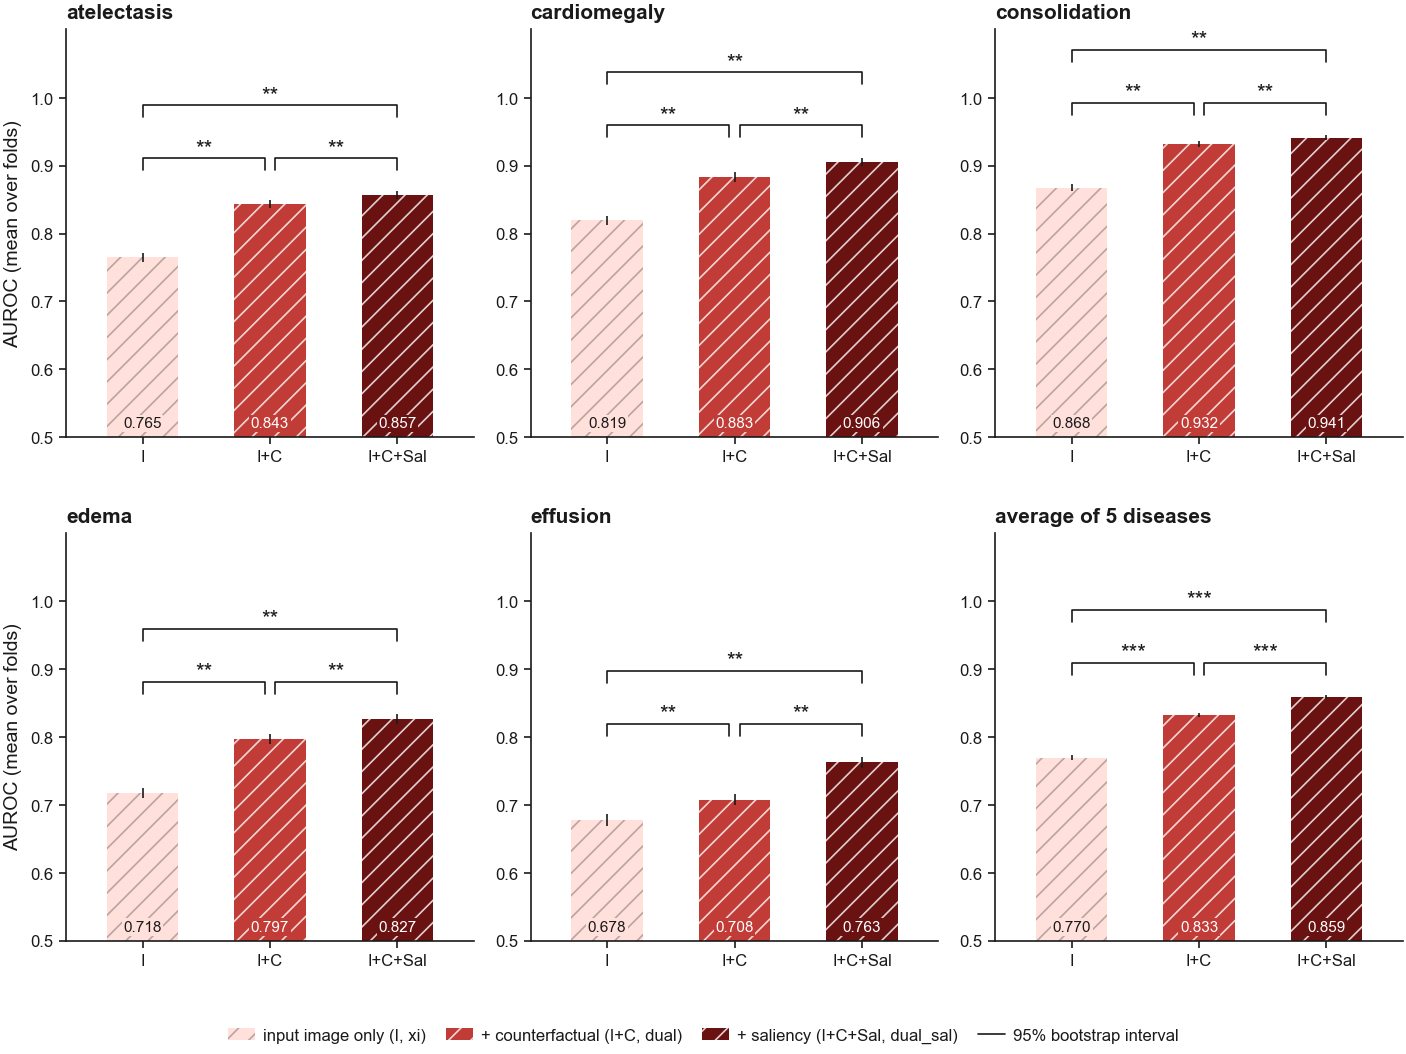

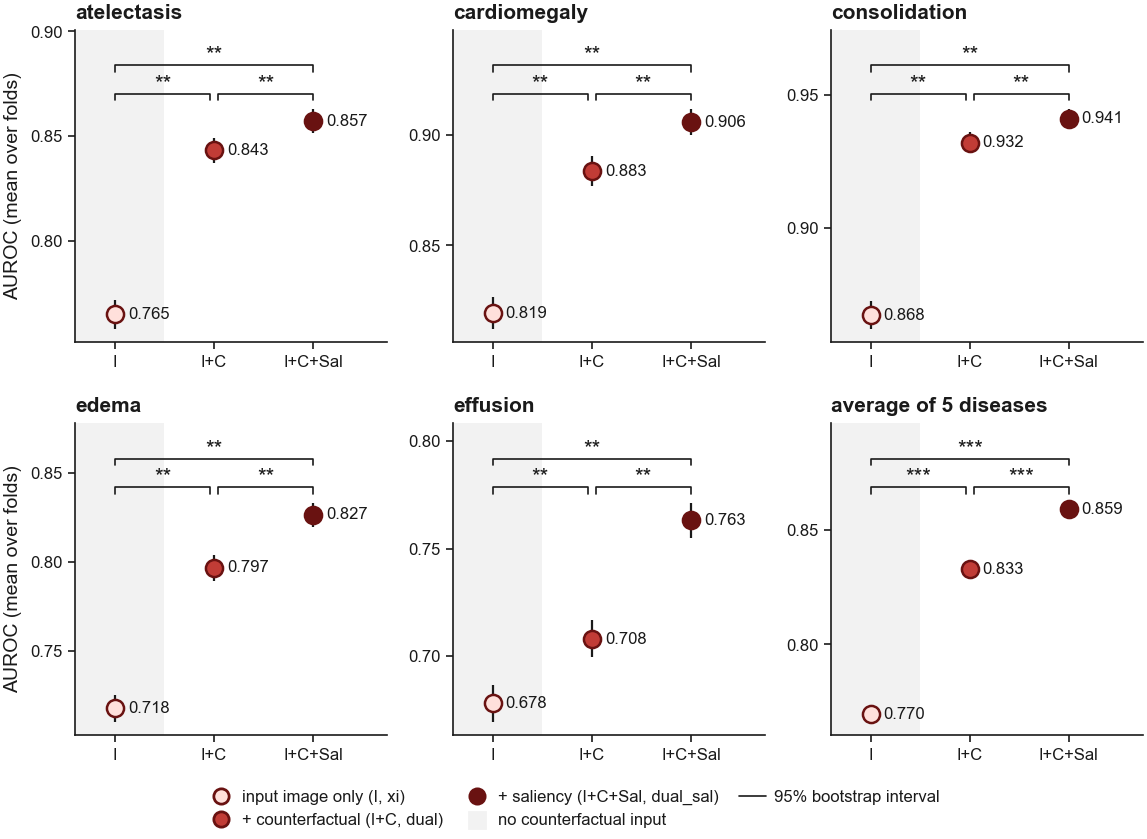

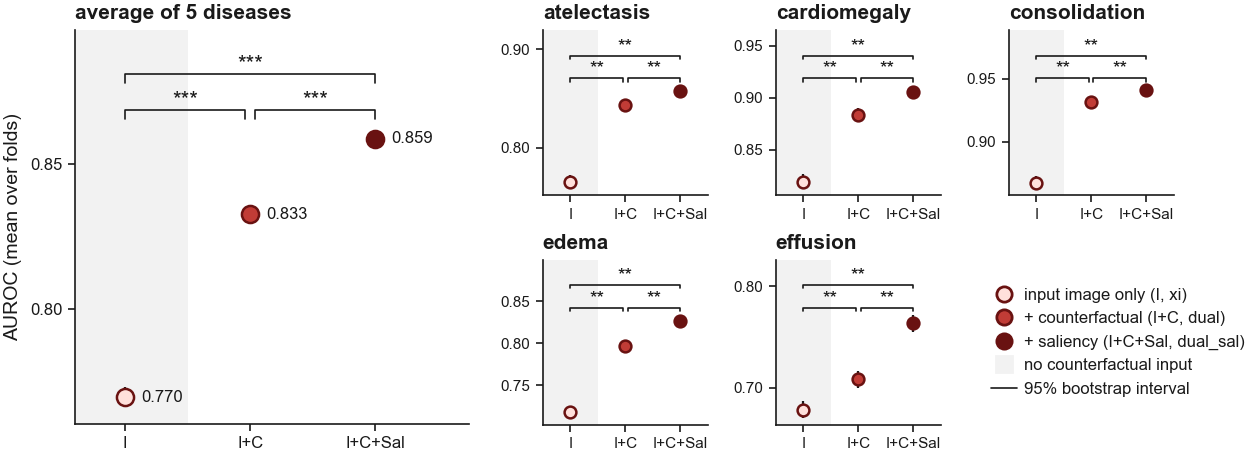

In [11]:
# The ladder is read from the bootstrap, like the attribute rungs, so bars and brackets always
# describe the same models.
CNN_FAMILIES      = BOOT_META["cnn_families"]           # xi -> dual -> dual_sal
CNN_FAMILY_NAMES  = list(CNN_FAMILIES)
CNN_FAMILY_COLORS = [TINT["cnn"], RAMP["cnn"][1], RAMP["cnn"][2]]
CNN_FAMILY_CMP = [(0.00, 0.96, "CNN dual - xi",       0),
                  (1.04, 2.00, "CNN dual_sal - dual", 0),
                  (0.00, 2.00, "CNN dual_sal - xi",   1)]


def cnn_family_scores(disease):
    """Mean-fold AUROC of each ladder rung at FINAL["k"], and both MSPs, for one disease."""
    k    = FINAL["k"]
    cnn  = load_cnn(disease, k)
    aucs = {key: per_fold_auc(cnn, f"cnn_{key}") for keys in CNN_FAMILIES.values() for key in keys}
    return ({f: float(np.mean([aucs[key] for key in keys])) for f, keys in CNN_FAMILIES.items()},
            msp_bases(load_attributes(disease, k), disease))


def cnn_family_bars(diseases=DISEASES, ncols=3, panel=(FULL / 3, 68 * MM)):
    k      = FINAL["k"]
    cols   = {f: [f"CNN {key}@K{k}" for key in keys] for f, keys in CNN_FAMILIES.items()}
    scores = {d: cnn_family_scores(d) for d in diseases}
    scores["AVERAGE"] = ({f: np.mean([scores[d][0][f] for d in diseases])
                          for f in CNN_FAMILY_NAMES},
                         mean_bases([scores[d][1] for d in diseases]))
    panels = list(diseases) + ["AVERAGE"]

    top  = max(boot_interval(d, cs)[1] for d in panels for cs in cols.values())
    ymax = 0.5 + (top - 0.5) / 0.74

    fig, axes = _grid(len(panels), ncols, panel=panel)
    for ax, d in zip(axes, panels):
        fam, base = scores[d]
        h  = np.array([fam[f] for f in CNN_FAMILY_NAMES])
        ci = np.array([boot_interval(d, cols[f]) for f in CNN_FAMILY_NAMES])
        bar_panel(ax, d, h, ci, CNN_FAMILY_COLORS, [CNN_LABELS[f] for f in CNN_FAMILY_NAMES],
                  CNN_FAMILY_CMP, None, ymax)
        ax.set_ylim(0.5, ymax)
        ax.set_yticks(np.arange(0.5, 1.001, 0.1))
    for ax in axes[::ncols]:
        ax.set_ylabel("AUROC (mean over folds)")

    fig.legend(handles=[diff_patch(TINT["cnn"], "input image only (I, xi)"),
                        diff_patch(RAMP["cnn"][1], "+ counterfactual (I+C, dual)"),
                        diff_patch(RAMP["cnn"][2], "+ saliency (I+C+Sal, dual_sal)"),
                        Line2D([], [], color=INK, lw=LW["axis"], label="95% bootstrap interval")],
               loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.03, 1, 0.99))
    return fig


save_fig(cnn_family_bars(), "aim1g_cnn_ladder_bars");


def cnn_family_points_args(diseases=DISEASES):
    """points_figure arguments of the CNN ladder, shared by the grid and the key figure."""
    k      = FINAL["k"]
    scores = {d: cnn_family_scores(d) for d in diseases}
    scores["AVERAGE"] = ({f: np.mean([scores[d][0][f] for d in diseases])
                          for f in CNN_FAMILY_NAMES},
                         mean_bases([scores[d][1] for d in diseases]))
    values = {d: ([s[0][f] for f in CNN_FAMILY_NAMES], s[1]) for d, s in scores.items()}
    cols   = [[f"CNN {key}@K{k}" for key in CNN_FAMILIES[f]] for f in CNN_FAMILY_NAMES]
    edge   = RAMP["cnn"][2]
    return dict(values=values, cols=cols, names=[CNN_LABELS[f] for f in CNN_FAMILY_NAMES],
                colors=CNN_FAMILY_COLORS, edges=[edge] * 3, cmps=CNN_FAMILY_CMP,
                legend=[pt_handle(TINT["cnn"], edge, "input image only (I, xi)"),
                        pt_handle(RAMP["cnn"][1], edge, "+ counterfactual (I+C, dual)"),
                        pt_handle(RAMP["cnn"][2], edge, "+ saliency (I+C+Sal, dual_sal)"),
                        patch_handle(SHADE, "no counterfactual input"), INTERVAL],
                shade=[0])


def cnn_family_points(diseases=DISEASES):
    """The CNN ladder as points: same models, values and brackets as the bars."""
    return points_figure(**cnn_family_points_args(diseases), msp=False)


save_fig(cnn_family_points(), "aim1g_cnn_ladder_points");
save_key_fig(points_key_figure(**cnn_family_points_args(), msp=False), "aim1g_cnn_ladder_points");


# Aim 2 - is it better than the baseline?

Aim 1 showed which inputs carry correctness signal, and how that depends on K. This section
asks the question that decides whether any of it is worth deploying: **does it beat MSP?**

**The models are the final system (`FINAL`), fixed in advance rather than searched**, exactly
as in `C2_evaluation.ipynb`: `I+C+D` and `dual_sal` at K=1, and their ensemble. Only the
ensemble's combiner (mean / rank / lr) is chosen, by mean fold AUROC. Fixing the models means
the comparison with MSP carries no selection on top of the ablation. The full ladders across
every config and every K are in Aim 1.


## 2a. Best model vs MSP

One question per metric, one point per disease: does the final system's strongest model -- the
best of the attribute model, the CNN and their ensemble by mean fold AUROC, the bootstrap's
`best_all` -- rank C0's errors better than the adjusted MSP (the predicted class's probability
at C0's Youden threshold, section 0)?

* **a, AUROC** -- gain over the adjusted MSP, zoomed to ±0.01.
* **b, E-AURC** -- reduction against the adjusted MSP, `E-AURC(MSP) - E-AURC(best)`, so right is
  better in both panels.

In each panel the dashed line **is** the adjusted MSP. The label above each point is the gain
and, in brackets, the **percentage of MSP's remaining gap it closes**: `gain / (1 - AUROC_MSP)` for
AUROC and `gain / E-AURC_MSP` for E-AURC. The average row is the mean gain and the mean of the per-task percentages (unrounded,
printed to one decimal). Tasks are ordered by C0's threshold, as in the appendix figure.
Whiskers are 95% paired bootstrap intervals. A **filled** point with `*` is significant after
Holm correction across the five tasks, within each panel separately (the AUROC average:
across the claims; the E-AURC average is a single test); an open point is not. Statistics: `bootstrapping_diffusion.ipynb` (claim 9 for AUROC, its E-AURC section for E-AURC, on the same draws).

Below, risk-coverage for the tasks with the largest and smallest AUROC gain. The curves sit on
top of each other at these effect sizes, so the bottom row draws the difference.


In [12]:
def best_attr(disease, model="MLP", ks=None):
    """The final system's attribute model, FINAL["attr"] at FINAL["k"].

    Returns (config, K, score vector, frame, auroc), the shape the search it replaces
    returned, so every caller is unchanged. `ks` is accepted and ignored: nothing is searched.
    """
    k  = FINAL["k"]
    df = load_attributes(disease, k)
    if df is None:
        return None
    col = f"{model}_{FINAL['attr']}_prob"
    return (FINAL["attr"], k, df[col], df, per_fold_auc(df, col))


def best_cnn(disease, ks=None):
    """The final system's CNN, FINAL["cnn"] at FINAL["k"].
    Returns (variant, K, frame, column, auroc). `ks` is ignored."""
    k, key = FINAL["k"], FINAL["cnn"]
    cnn = load_cnn(disease, k)
    col = f"cnn_{key}"
    if cnn is None or col not in cnn.columns or not cnn[col].notna().all():
        return None
    return (key, k, cnn, col, per_fold_auc(cnn, col))


def best_ens(disease, ks=None):
    """The final ensemble at FINAL["k"] with its best combiner, by mean fold AUROC -- the same
    pick as the bootstrap's `best_ens`. Returns (combiner, K, frame, column, auroc); the frame
    carries the C0 probability so MSP is scored on exactly the ensemble's rows."""
    k   = FINAL["k"]
    ref = load_attributes(disease, k)
    p   = os.path.join(C2, disease, SOURCE, f"cf_{k}", "ensemble", "oof_predictions.csv")
    if ref is None or not os.path.exists(p):
        return None
    m, best = pd.read_csv(p).merge(ref[["path", f"{disease}_prob"]], on="path", how="inner"), None
    for col in [x for x in m.columns if x.startswith("ens_")]:
        a = per_fold_auc(m, col)
        if best is None or a > best[-1]:
            best = (col[len("ens_"):], k, m, col, a)
    return best


def check_bootstrap_picks(diseases=DISEASES, model="MLP"):
    """Before any bootstrap statistic is drawn next to a model, check both notebooks mean the
    same one -- otherwise a star would belong to a different model than the one drawn."""
    rows = []
    for d in diseases:
        a, c, e, p = best_attr(d, model), best_cnn(d), best_ens(d), BOOT_META["picks"][d]
        rows.append({"disease": d,
                     "attr (here)": f"{a[0]}@K{a[1]}", "attr (bootstrap)": p["best_attr"],
                     "CNN (here)": f"CNN {c[0]}@K{c[1]}", "CNN (bootstrap)": p["best_cnn"],
                     "ens (here)": f"ENS {e[0]}@K{e[1]}", "ens (bootstrap)": p["best_ens"]})
    t = pd.DataFrame(rows).set_index("disease")
    t["match"] = ((t["attr (here)"] == t["attr (bootstrap)"])
                  & (t["CNN (here)"] == t["CNN (bootstrap)"])
                  & (t["ens (here)"] == t["ens (bootstrap)"]))
    if not t["match"].all():
        display(t)
        raise RuntimeError("bootstrapping_diffusion.ipynb picked different models than this "
                           "notebook -- its statistics do not describe the models plotted here")
    return t


check_bootstrap_picks()


,attr (here),attr (bootstrap),CNN (here),CNN (bootstrap),ens (here),ens (bootstrap),match
disease,,,,,,,
atelectasis,I+C+D@K1,I+C+D@K1,CNN dual_sal@K1,CNN dual_sal@K1,ENS rank@K1,ENS rank@K1,True
cardiomegaly,I+C+D@K1,I+C+D@K1,CNN dual_sal@K1,CNN dual_sal@K1,ENS lr@K1,ENS lr@K1,True
consolidation,I+C+D@K1,I+C+D@K1,CNN dual_sal@K1,CNN dual_sal@K1,ENS rank@K1,ENS rank@K1,True
edema,I+C+D@K1,I+C+D@K1,CNN dual_sal@K1,CNN dual_sal@K1,ENS rank@K1,ENS rank@K1,True
effusion,I+C+D@K1,I+C+D@K1,CNN dual_sal@K1,CNN dual_sal@K1,ENS rank@K1,ENS rank@K1,True


,,model,msp,gain,gap,lo,hi,p_adj
metric,disease,,,,,,,
AUROC,atelectasis,ENS rank@K1,0.8644,-0.0043,-0.0314,-0.0067,-0.0017,0.0064
E-AURC,atelectasis,ENS rank@K1,0.0625,-0.0024,-0.0377,-0.0037,-0.0009,0.0060
AUROC,cardiomegaly,ENS lr@K1,0.9146,-0.0009,-0.0102,-0.0032,0.0016,0.6600
E-AURC,cardiomegaly,ENS lr@K1,0.0221,-0.0002,-0.0099,-0.0012,0.0008,0.6764
AUROC,consolidation,ENS rank@K1,0.9474,-0.0041,-0.0772,-0.0062,-0.0019,0.0010
E-AURC,consolidation,ENS rank@K1,0.0222,-0.0013,-0.0568,-0.0025,-0.0001,0.1020
AUROC,edema,ENS rank@K1,0.8309,0.0014,0.0082,-0.0014,0.0041,0.6600
E-AURC,edema,ENS rank@K1,0.0515,0.0008,0.0151,-0.0003,0.0019,0.3216
AUROC,effusion,ENS rank@K1,0.7824,-0.0032,-0.0149,-0.0072,0.0006,0.2940


/tmp/ipykernel_839693/1088746339.py:185: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0.11, 1, 1), w_pad=1.5)


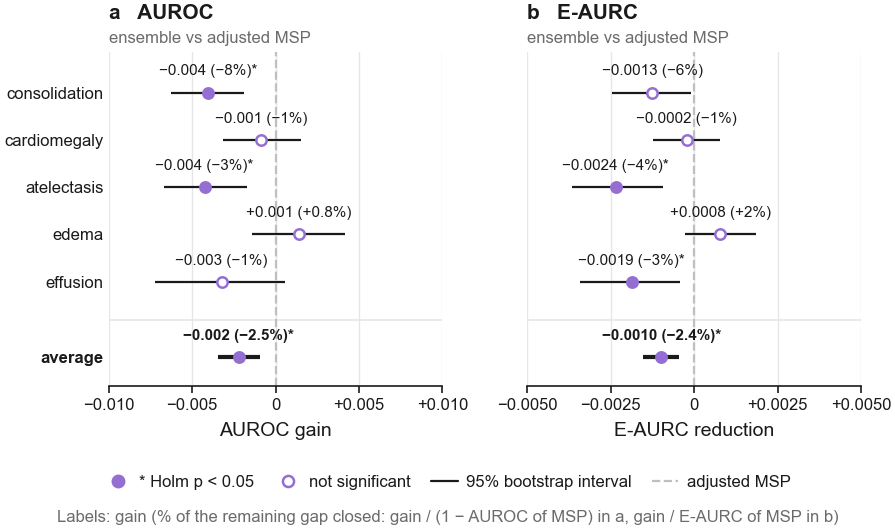

In [13]:
import c2_boot_extra as BX

# The E-AURC panel's statistics: written by the E-AURC section of the bootstrapping notebook,
# on the same draws as the AUROC export (it checks that before writing).
E_FILE = BOOT_FILES["deltas.csv"].replace("deltas.csv", "eaurc_deltas.csv")
if not os.path.exists(E_FILE):
    raise FileNotFoundError(f"{E_FILE} missing -- run the E-AURC section of the bootstrapping notebook")
E_BOOT = pd.read_csv(E_FILE)

ALPHA = BOOT_META["alpha"]


def star(p_adj):
    """One mark, one meaning -- the legend's: Holm-adjusted p < ALPHA. The bootstrap's p floor
    (1/N_BOOT) times the Holm factor makes finer star levels an artefact of N_BOOT."""
    return "*" if p_adj < ALPHA else ""


def final_model(disease, model="MLP"):
    """The final system's strongest model on one disease: the best of the attribute model, the
    CNN and the ensemble by mean fold AUROC -- the bootstrap's `best_all`, checked against it.

    Returns (bootstrap name, frame carrying the C0 probability, score column, auroc). Each
    model is scored on the rows it has, and MSP is recomputed on those same rows."""
    k, ref = FINAL["k"], load_attributes(disease, FINAL["k"])
    cands = []
    a = best_attr(disease, model)
    if a:
        cfg, _, _, adf, auc = a
        cands.append((f"{cfg}@K{k}", adf, f"{model}_{cfg}_prob", auc))
    c = best_cnn(disease)
    if c:
        key, _, cnn, col, _ = c
        m = cnn.merge(ref[["path", f"{disease}_prob"]], on="path", how="inner")
        cands.append((f"CNN {key}@K{k}", m, col, per_fold_auc(m, col)))
    e = best_ens(disease)
    if e:
        meth, _, m, col, auc = e
        cands.append((f"ENS {meth}@K{k}", m, col, auc))
    best = max(cands, key=lambda t: t[-1])
    pick = BOOT_META["picks"][disease]["best_all"]
    if best[0] != pick:
        raise RuntimeError(f"{disease}: the best model here is {best[0]}, the bootstrap tested "
                           f"{pick} -- its statistics would describe another model")
    return best


def fold_e_aurc(df, score):
    """Mean-fold E-AURC, mergesort ties -- the statistic the E-AURC bootstrap resamples."""
    s = pd.Series(np.asarray(score, float), index=df.index)
    return float(np.mean([BX.e_aurc(g["correct"], s.loc[g.index]) for _, g in df.groupby("fold")]))


def msp_gains(diseases=DISEASES, model="MLP"):
    """One row per (disease, metric): the best model's gain over the adjusted MSP (positive =
    better), the share of MSP's remaining gap it closes, and the bootstrap interval and test.

    AUROC   gain = AUROC(best) - AUROC(MSP)      gap closed = gain / (1 - AUROC(MSP))
    E-AURC  gain = E-AURC(MSP) - E-AURC(best)    gap closed = gain / E-AURC(MSP)

    The AVERAGE row is the mean gain and the MEAN gap closed over diseases; its interval and
    test are the bootstrap's AVERAGE rows (averaged inside each replicate)."""
    rows = []
    for d in diseases:
        name, df, col, auc = final_model(d, model)
        base = msp(df, d)
        a_msp = per_fold_auc(df, base)
        e_msp, e_best = fold_e_aurc(df, base), fold_e_aurc(df, df[col])
        ra = boot_row("best overall - MSP", d)
        re = E_BOOT[E_BOOT.disease == d].iloc[0]
        rows += [dict(disease=d, metric="AUROC", model=name, msp=a_msp, gain=auc - a_msp,
                      gap=(auc - a_msp) / (1 - a_msp), lo=ra.lo, hi=ra.hi, p_adj=ra.p_adj),
                 dict(disease=d, metric="E-AURC", model=name, msp=e_msp, gain=e_msp - e_best,
                      gap=(e_msp - e_best) / e_msp, lo=re.lo, hi=re.hi, p_adj=re.p_adj)]
    per = pd.DataFrame(rows)
    for metric, st in (("AUROC", boot_row("best overall - MSP", "AVERAGE")),
                       ("E-AURC", E_BOOT[E_BOOT.disease == "AVERAGE"].iloc[0])):
        g = per[per.metric == metric]
        rows.append(dict(disease="AVERAGE", metric=metric, model="", msp=g.msp.mean(),
                         gain=g.gain.mean(), gap=g.gap.mean(), lo=st.lo, hi=st.hi,
                         p_adj=st.p_adj))
    return pd.DataFrame(rows)


def _signed(x, dec=3):
    return f"{x:+.{dec}f}".replace("-", "−")


def _gain_formatter(ax, dec):
    ax.xaxis.set_major_formatter(plt.FuncFormatter(
        lambda x, _: "0" if abs(x) < 1e-12 else _signed(x, dec)))


def plotted_method():
    """What figure 2a draws, in words: the bootstrap's best_all, which is a family pick per
    disease. One word when every disease agrees (in practice: the ensemble)."""
    kind  = {"ENS": "ensemble", "CNN": "CNN"}
    names = {kind.get(BOOT_META["picks"][d]["best_all"].split()[0], "attribute model")
             for d in DISEASES}
    return names.pop() if len(names) == 1 else "best model"


METHOD = plotted_method()
# (metric, title, x label, half-width of the x range or None = fit the intervals)
GAIN_PANELS = [("AUROC",  "AUROC",  "AUROC gain",       0.01),
               ("E-AURC", "E-AURC", "E-AURC reduction", None)]


def msp_forest(gains=None, figsize=(118 * MM, 70 * MM)):
    """Figure 2a: the best model's gain over the adjusted MSP, in AUROC (a) and E-AURC (b).

    The dashed line in each panel IS the adjusted MSP: right of it is a win, left a loss.
    One point per disease, ordered by C0's threshold, plus their average, set apart below; the
    label above each point is the gain and, in brackets, the share of MSP's remaining gap it
    closes (the average: the mean of the per-task shares, unrounded). Filled and `*` mean
    the same thing, Holm p < ALPHA. AUROC is zoomed to +/-0.01 so the intervals are readable;
    E-AURC is on its own scale (a different metric). Square panels, one disease axis."""
    gains = msp_gains() if gains is None else gains
    # Ordered by C0's Youden threshold, low to high -- the order of the appendix MSP figure,
    # so the two cross-reference row for row.
    order = sorted((d for d in DISEASES if d in set(gains.disease)), key=c0_threshold) + ["AVERAGE"]
    ys    = list(range(len(order) - 1)) + [len(order) - 1 + 0.6]     # average set apart
    sep   = (ys[-2] + ys[-1]) / 2

    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)
    for ax, letter, (metric, title, xlabel, half) in zip(axes, "ab", GAIN_PANELS):
        g = gains[gains.metric == metric].set_index("disease").loc[order]
        reach = max(g.lo.abs().max(), g.hi.abs().max())
        if half is None or reach > half:          # never clip an interval
            step = 10 ** np.floor(np.log10(reach))
            half = np.ceil(reach * 1.15 / step) * step
        ax.set_xlim(-half, half)
        # Ticks at 0, +/-half/2, +/-half, with the fewest decimals that print every one exactly
        # (0.0025 -> 4). Values get 3 decimals on an AUROC-sized range, 4 on a smaller one.
        ticks = np.array([-1, -0.5, 0, 0.5, 1]) * half
        tdec  = next(k for k in range(1, 8) if np.allclose(np.round(ticks, k), ticks, rtol=0, atol=1e-12))
        dec   = 3 if half >= 0.01 else 4

        ax.axvline(0.0, color=GREY, ls="--", lw=LW["ref"], zorder=1)
        ax.axhline(sep, color=HAIR, lw=LW["axis"], zorder=0)
        for y, (d, r) in zip(ys, g.iterrows()):
            sig = r.p_adj < ALPHA
            avg = d == "AVERAGE"
            # The average's interval is the narrowest, so it gets the heavier line and the dot
            # stays small -- otherwise the dot covers the whisker.
            ax.plot([r.lo, r.hi], [y, y], color=INK, lw=LW["line"] if avg else LW["ref"],
                    solid_capstyle="butt", zorder=2)
            ax.scatter([r.gain], [y], s=14, zorder=3,
                       c=[ENS if sig else "white"], edgecolors=[ENS], linewidths=0.9)
            # Shares under 1% keep a decimal, so -0.5% is not printed as "-0%".
            # The average is the mean of the unrounded per-task shares; it keeps one decimal so
            # it is not checked against the rounded task labels.
            pct   = _signed(100 * r.gap, 1 if avg or abs(100 * r.gap) < 0.95 else 0)
            label = f"{_signed(r.gain, dec)} ({pct}%){star(r.p_adj)}"
            ax.text(r.gain, y - 0.3, label, ha="center", va="bottom", fontsize=FS["tiny"],
                    color=INK, fontweight="bold" if avg else "normal", zorder=4)

        ax.set_xticks(ticks)
        _gain_formatter(ax, tdec)
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", zorder=0); ax.set_axisbelow(True)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0)
        ax.set_box_aspect(1)
        ax.set_title(f"{letter}   {title}", pad=12)
        ax.text(0.0, 1.02, f"{METHOD} vs adjusted MSP", transform=ax.transAxes, ha="left",
                va="bottom",
                fontsize=FS["small"], color=MUTED)

    axes[0].set_yticks(ys, [d if d != "AVERAGE" else "average" for d in order])
    axes[0].get_yticklabels()[-1].set_fontweight("bold")
    axes[0].set_ylim(ys[-1] + 0.6, -0.85)

    legend = [Line2D([], [], ls="none", marker="o", ms=4, color=ENS,
                     label=f"* Holm p < {ALPHA:g}"),
              Line2D([], [], ls="none", marker="o", ms=4, mfc="white", mec=ENS, mew=0.9,
                     label="not significant"),
              Line2D([], [], color=INK, lw=LW["ref"], label="95% bootstrap interval"),
              msp_handle("adjusted MSP")]
    fig.legend(handles=legend, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.045))
    fig.text(0.5, 0.0, "Labels: gain (% of the remaining gap closed: gain / (1 − AUROC of MSP) "
             "in a, gain / E-AURC of MSP in b)", ha="center", va="bottom",
             fontsize=FS["small"], color=MUTED)
    for _ in range(2):                 # second pass measures the squared axes
        fig.tight_layout(rect=(0, 0.11, 1, 1), w_pad=1.5)
    return fig


MSP_GAINS = msp_gains()
display(MSP_GAINS.round(4).set_index(["metric", "disease"]))
save_fig(msp_forest(MSP_GAINS), "aim2a_best_vs_msp");


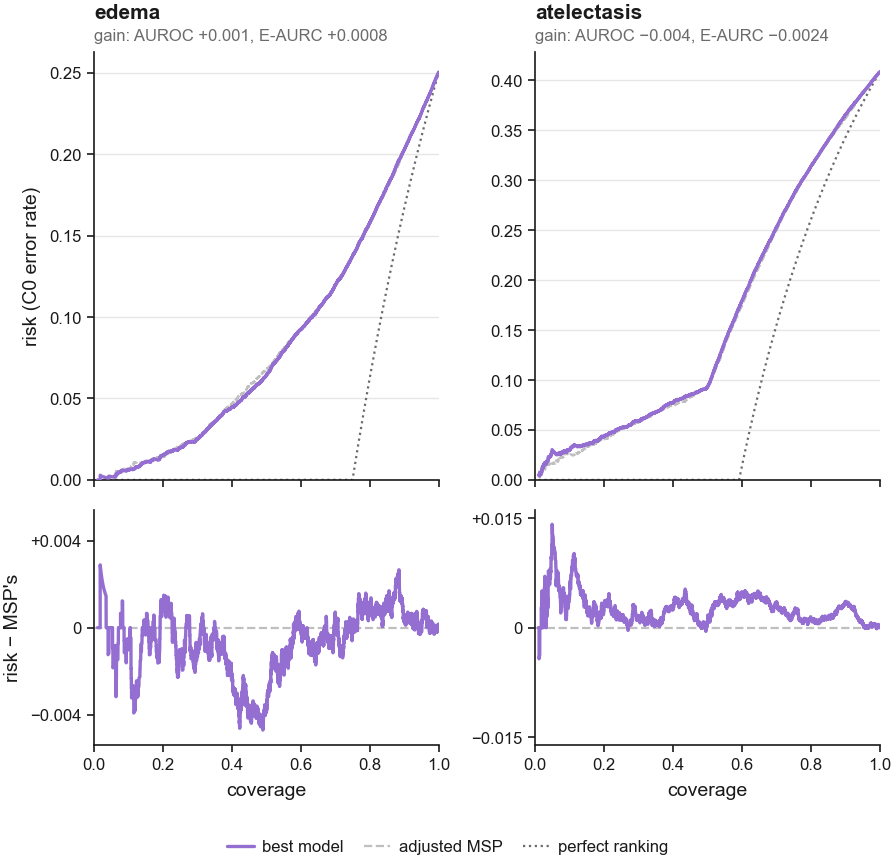

In [14]:
def risk_coverage(correct, score, min_n=200):
    """Retain the most-confident-first prefix. risk(c) = C0 error rate among the retained.
    Same as C2_evaluation.ipynb: mergesort ties, left tail trimmed at `min_n` for the plot."""
    order = np.argsort(-np.asarray(score, float), kind="mergesort")
    y = np.asarray(correct, int)[order]
    k = np.arange(1, len(y) + 1)
    cov, risk = k / len(y), np.cumsum(1 - y) / k
    return cov[min_n - 1:], risk[min_n - 1:]


# Risk-coverage for two tasks: the one where the best model gains most AUROC over the adjusted
# MSP, and the one where it gains least -- the two ends of panel a, picked from MSP_GAINS so the
# choice follows the numbers rather than being made by eye.
_a = MSP_GAINS[(MSP_GAINS.metric == "AUROC") & (MSP_GAINS.disease != "AVERAGE")]
RC_TASKS = [_a.loc[_a.gain.idxmax(), "disease"], _a.loc[_a.gain.idxmin(), "disease"]]


def rc_figure(tasks=RC_TASKS, figsize=(118 * MM, 112 * MM), min_n=200):
    """Top: risk (C0's error rate among the retained) against coverage, retaining the most
    confident first -- the best model, the adjusted MSP and a perfect ranking. Bottom: the best
    model's risk minus MSP's at each coverage, below zero = fewer errors kept.

    The curves differ by a few thousandths, so on the top row they overlap; the bottom row is
    where the difference is read. Pooled over the out-of-fold predictions, the left tail
    trimmed at `min_n` retained samples (see risk_coverage)."""
    fig, axes = plt.subplots(2, len(tasks), figsize=figsize, sharex=True,
                             gridspec_kw={"height_ratios": [1.0, 0.55]}, squeeze=False)
    for j, d in enumerate(tasks):
        name, df, col, _ = final_model(d)
        top, bot = axes[0, j], axes[1, j]
        cov, r_best = risk_coverage(df["correct"], df[col], min_n)
        _,   r_msp  = risk_coverage(df["correct"], msp(df, d), min_n)
        _,   r_opt  = risk_coverage(df["correct"], df["correct"].astype(float), min_n)

        top.plot(cov, r_opt, color=MUTED, ls=":", lw=LW["ref"], zorder=1)
        top.plot(cov, r_msp, color=GREY, ls="--", lw=LW["ref"], zorder=2)
        top.plot(cov, r_best, color=ENS, lw=LW["line"] * 0.8, zorder=3)
        g = MSP_GAINS.set_index(["metric", "disease"])
        top.set_title(d, pad=12)
        top.text(0.0, 1.02, f"gain: AUROC {_signed(g.loc[('AUROC', d), 'gain'])}, "
                            f"E-AURC {_signed(g.loc[('E-AURC', d), 'gain'], 4)}",
                 transform=top.transAxes, ha="left", va="bottom", fontsize=FS["small"],
                 color=MUTED)
        top.set_ylim(0, None)
        top.grid(axis="y", zorder=0); top.set_axisbelow(True)

        diff = r_best - r_msp
        bot.axhline(0.0, color=GREY, ls="--", lw=LW["ref"], zorder=1)
        bot.plot(cov, diff, color=ENS, lw=LW["line"] * 0.8, zorder=2)
        lim = np.abs(diff[cov >= 0.05]).max() * 1.15        # ignore the noisy left edge
        bot.set_ylim(-lim, lim)
        bot.set_xlim(0, 1)
        bot.set_xlabel("coverage")
        bot.yaxis.set_major_locator(plt.MaxNLocator(3, symmetric=True))
        bot.yaxis.set_major_formatter(plt.FuncFormatter(
            lambda y, _: "0" if abs(y) < 1e-12 else _signed(y, 3)))
    axes[0, 0].set_ylabel("risk (C0 error rate)")
    axes[1, 0].set_ylabel("risk − MSP's")
    legend = [Line2D([], [], color=ENS, lw=LW["line"] * 0.8, label="best model"),
              msp_handle("adjusted MSP"),
              Line2D([], [], color=MUTED, ls=":", lw=LW["ref"], label="perfect ranking")]
    fig.legend(handles=legend, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    return fig


save_fig(rc_figure(), "aim2a_risk_coverage");


## 2b. Ensembling attributes and CNNs

The two families read different things - one the counterfactual *attributes*, the other the
*images* - so the question 2a leaves open is whether they are complementary: does combining
them rank C0's errors better than either alone?

Computed by `c2_ensemble.py`, not here; this cell only reads its `ensemble_summary.csv`. It
combines the final system's two models (`FINAL`: `I+C+D` and `dual_sal`, at K=1) three ways:

| Combiner | What it does |
|---|---|
| `mean` | Average of the two probabilities. Assumes they are comparably calibrated. |
| `rank` | Average of within-fold percentile ranks. Calibration-free, so it asks whether the two *order* cases differently. |
| `lr` | Logistic regression on the two probabilities, fitted leave-one-fold-out. |

**The dashed line is the better of the two inputs, not MSP.** If both components already clear
MSP, an ensemble that only beats the baseline has shown nothing; a bar has to clear the dashed
line to mean anything.

**Brackets** run from the better component to each combiner and carry the paired bootstrap test
of that difference from `bootstrapping_diffusion.ipynb`, Holm-adjusted across the combiner x
disease tests of this figure: `***` / `**` / `*` is `p_adj` < 0.001 / 0.01 / 0.05, `n.s.` otherwise.


/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


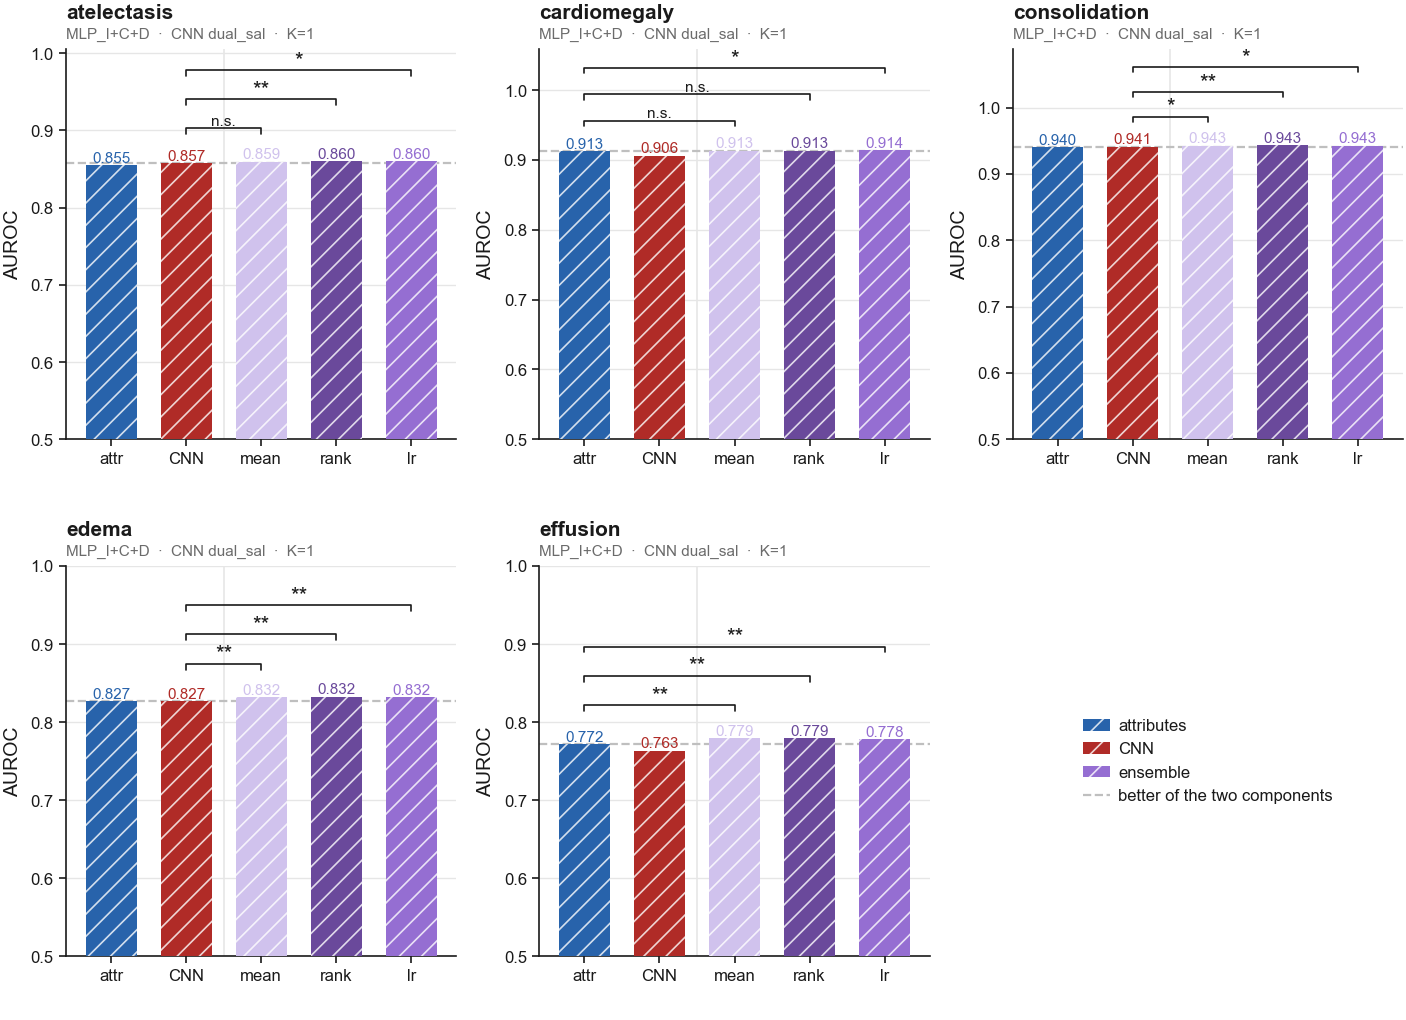

In [15]:
ENS_METHODS = ["mean", "rank", "lr"]
# The combiners are a MIX of families, so they take the ensemble purple rather than
# borrowing a family hue -- which would claim they belong to one of the inputs.
# They are separated from each other by lightness, not colour.
ENS_COLOR   = {"mean": "#D0C2ED", "rank": "#6A499B", "lr": ENS}

# Fixed AUROC window, shared by every panel so heights compare across diseases.
Y_LO, Y_HI = 0.5, 1.0


def load_ensemble(disease, k, source=None):
    """`ensemble_summary.csv` for one disease and K, or None if that run is absent.
    Written by c2_ensemble.py; nothing is fitted here."""
    p = os.path.join(C2, disease, source or SOURCE, f"cf_{k}", "ensemble",
                     "ensemble_summary.csv")
    if not os.path.exists(p):
        return None
    df   = pd.read_csv(p)
    comp = df[df["kind"] == "component"].set_index("members")["auc_mean"]
    ens  = df[df["kind"] == "ensemble"].set_index("method")
    if comp.empty or ens.empty:
        return None
    # members is "<model>_prob"; only the attribute one carries an estimator prefix.
    attr = next((m for m in comp.index if m.split("_")[0] in ("MLP", "LR", "RF")), None)
    cnn  = next((m for m in comp.index if m != attr), None)
    if attr is None or cnn is None:
        return None
    return {"k": k, "attr": (attr[:-5], float(comp[attr])),
            "cnn": (cnn[:-5], float(comp[cnn])), "ens": ens}


def best_ensemble(disease, ks=None):
    """The final ensemble, at FINAL["k"]. Nothing is searched: the members and K are FINAL,
    fixed before looking at the ensemble, so a lucky combiner cannot pick the row. `ks` is ignored."""
    return load_ensemble(disease, FINAL["k"])


def check_bootstrap_ensemble(diseases=DISEASES):
    """Same guard as check_bootstrap_picks, for these panels: the bootstrap must have tested
    the K, the two components and the better component that the panels draw."""
    bad = []
    for d in diseases:
        e = best_ensemble(d)
        if e is None:
            continue
        k    = e["k"]
        attr = f"{e['attr'][0].split('_', 1)[1]}@K{k}"          # "MLP_I+C+D" -> "I+C+D@K1"
        cnn  = f"CNN {e['cnn'][0]}@K{k}"
        here = (k, attr, cnn, attr if e["attr"][1] >= e["cnn"][1] else cnn)
        p    = BOOT_META["picks"][d]
        boot = (p["ens_k"], p["ens_attr"], p["ens_cnn"], p["ens_best_comp"])
        if here != boot:
            bad.append(f"  {d}: here {here}, bootstrap {boot}")
    if bad:
        raise RuntimeError("bootstrapping_diffusion.ipynb tested different ensembles than these "
                           "panels draw -- its statistics do not describe them:\n" + "\n".join(bad))


def ensemble_panel(ax, disease):
    """One disease: the two components and the three combiners, on an absolute axis.

    Absolute AUROC rather than a delta, because the question is where the ensembles sit
    RELATIVE TO THE BETTER COMPONENT -- which is a line on this axis, not a zero.
    """
    e = best_ensemble(disease)
    if e is None:
        ax.text(0.5, 0.5, f"{disease}\nno ensemble run", transform=ax.transAxes,
                ha="center", va="center", fontsize=FS["small"], color=MUTED)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_box_aspect(1)
        return

    (acfg, aauc), (ckey, cauc) = e["attr"], e["cnn"]
    names = ["attr", "CNN"] + ENS_METHODS
    vals  = [aauc, cauc] + [float(e["ens"].loc[m, "auc_mean"])
                            if m in e["ens"].index else np.nan for m in ENS_METHODS]
    # attributes blue, CNN red -- the same hues they carry everywhere else.
    cols  = [BLUE, RED] + [ENS_COLOR[m] for m in ENS_METHODS]

    x = np.arange(len(names))
    msp_line(ax, max(aauc, cauc))
    for xi, v, c in zip(x, vals, cols):
        if np.isnan(v):
            continue
        diff_bar(ax, xi, v, c, width=0.68, zorder=3)
        ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=FS["tiny"],
                color=c, zorder=4)

    # Bracket geometry is a fraction of the AXIS span, not of the data spread (thousandths)
    # -- otherwise the three brackets collapse onto one line.
    span  = Y_HI - Y_LO
    first = max(v for v in vals if v == v) + 0.07 * span    # clears the tallest value label
    step  = 0.075 * span                                    # gap between stacked brackets
    tick  = 0.015 * span                                    # bracket leg height
    best_x = 0 if aauc >= cauc else 1
    drawn  = [m for m in ENS_METHODS if m in e["ens"].index]
    for j, m in enumerate(drawn):
        bracket(ax, best_x, 2 + ENS_METHODS.index(m), first + step * j, tick,
                stars(boot_row(f"ENS {m} - better component", disease).p_adj))

    # Extend past 1.0 only as far as the brackets need; ticks stop at 1.0.
    ax.set_ylim(Y_LO, max(Y_HI, first + step * max(len(drawn) - 1, 0) + 0.07 * span))
    ax.set_yticks(np.arange(Y_LO, Y_HI + 1e-9, 0.1))
    ax.axvline(1.5, color=HAIR, lw=LW["axis"], zorder=0)      # components | ensembles
    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=FS["small"])
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.set_ylabel("AUROC")
    ax.set_title(disease, pad=11)
    ax.text(0.0, 1.02, f"{acfg}  ·  CNN {ckey}  ·  K={e['k']}", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=FS["tiny"], color=MUTED)
    ax.grid(axis="y", zorder=0); ax.set_axisbelow(True)
    ax.set_box_aspect(1)


check_bootstrap_ensemble()
fig, axes = _grid(len(DISEASES), 3, panel=(FULL / 3, 68 * MM))
for ax, d in zip(axes, DISEASES):
    ensemble_panel(ax, d)
corner_legend(fig, len(DISEASES), 3,
              [diff_patch(BLUE, "attributes"), diff_patch(RED, "CNN"),
               diff_patch(ENS, "ensemble"),
               msp_handle("better of the two components")])
save_fig(fig, "aim2b_ensemble")

/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


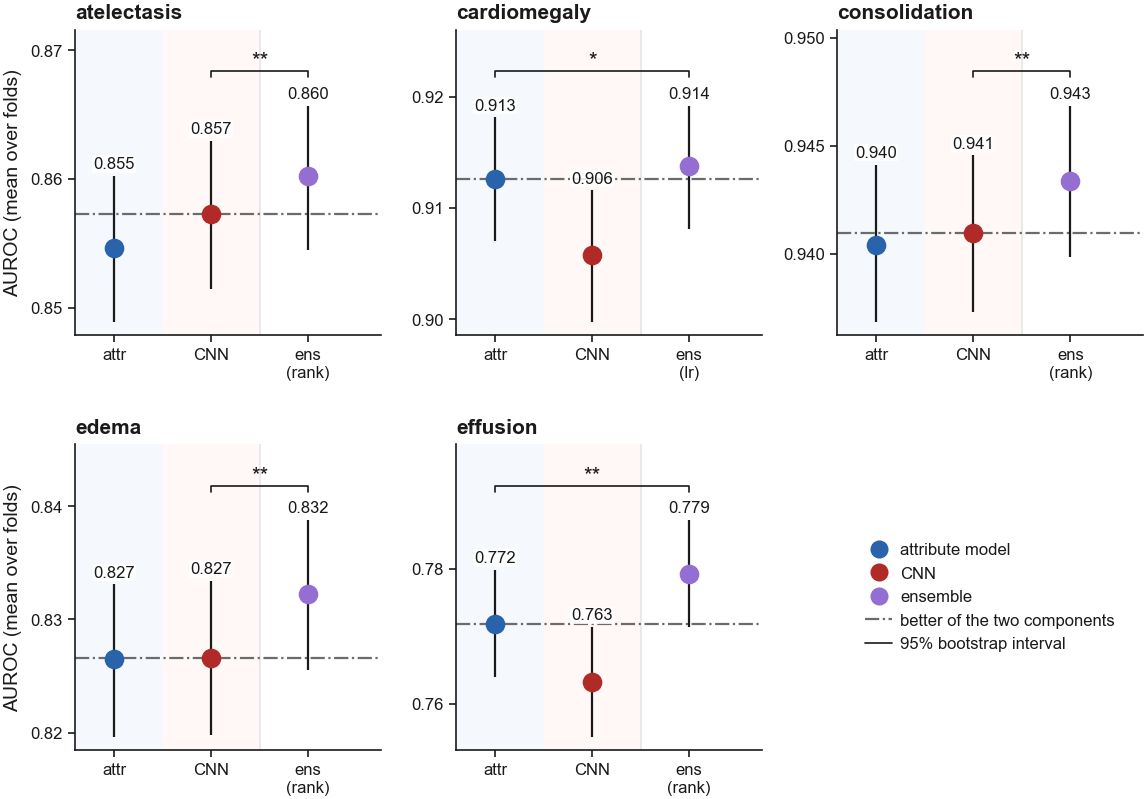

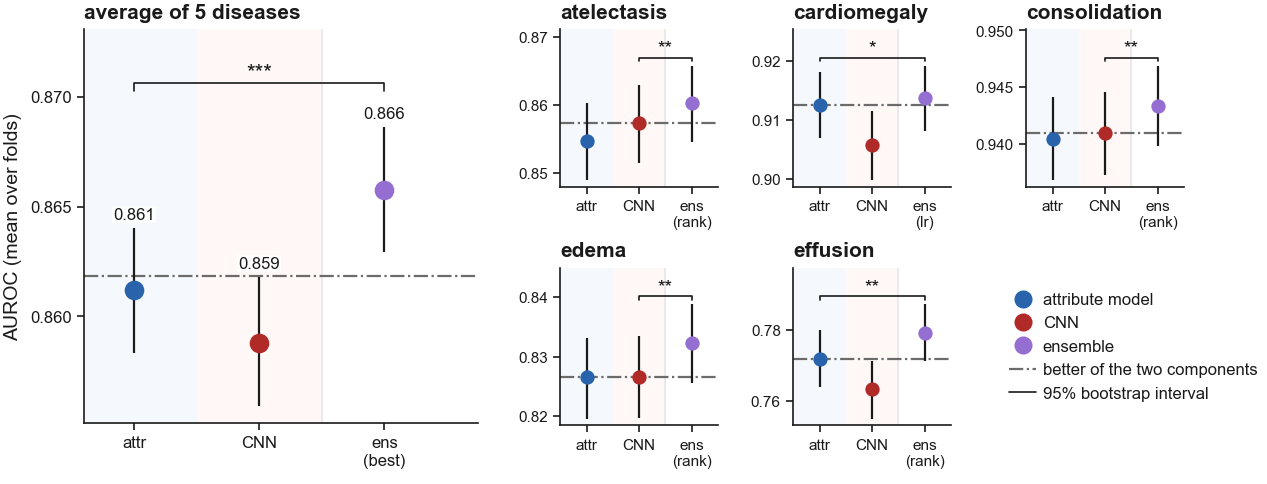

In [16]:
# ── Points + 95% bootstrap whiskers: the ensemble comparison without bars ──
# Same models, values and brackets as the bars above, drawn like 1d-1f: each panel zooms to
# its own intervals, so compare models within a panel, not heights across panels. The
# bracket origin is the better component, which differs by disease, so the panels are drawn
# here rather than through points_figure (one bracket list for every panel).
# Only the best combiner is drawn (best_ens: highest mean-fold AUROC, the bootstrap's pick);
# all three are in the bars above and the appendix table.
# Better component, in the points panels: not dashed, which is MSP's style there.
BEST_COMP_LS = "-."


def avg_interval(cols, level=0.95):
    """boot_interval for AVERAGE when the model differs by disease: `cols` is {disease: column},
    averaged inside each replicate."""
    v = np.mean([BOOT_REPS[d][c].to_numpy() for d, c in cols.items()], axis=0)
    a = (1 - level) / 2 * 100
    return np.percentile(v, [a, 100 - a])


def ensemble_specs(diseases=DISEASES):
    """{panel: points_panel arguments, plus `best` = the better component's AUROC}. No MSP: the
    ensemble is judged against its better component, the dash-dotted line. The AVERAGE
    panel joins once every disease has run: each disease's own components and combiner,
    averaged inside each replicate, with the bootstrap's `ensemble - best single` test on the
    average as its bracket (from the better of the two averaged components)."""
    specs, picks = {}, {}
    for d in diseases:
        e = best_ensemble(d)
        if e is None:
            continue
        (acfg, aauc), (ckey, cauc) = e["attr"], e["cnn"]
        p     = BOOT_META["picks"][d]
        drawn = [m for m in [best_ens(d)[0]] if m in e["ens"].index]
        cols  = [[p["ens_attr"]], [p["ens_cnn"]]] + [[p[f"ens_{m}"]] for m in drawn]
        specs[d] = dict(h=np.array([aauc, cauc] + [float(e["ens"].loc[m, "auc_mean"]) for m in drawn]),
                        ci=np.array([boot_interval(d, c) for c in cols]),
                        colors=[BLUE, RED] + [ENS] * len(drawn),
                        names=["attr", "CNN"] + [f"ens\n({m})" for m in drawn],
                        cmps=[(0 if aauc >= cauc else 1, 2 + j, f"ENS {m} - better component", j)
                              for j, m in enumerate(drawn)],
                        best=max(aauc, cauc))
        picks[d] = [c[0] for c in cols] + drawn
    if len(specs) == len(DISEASES) and all(len(v) == 4 for v in picks.values()):
        h     = np.mean([specs[d]["h"] for d in DISEASES], axis=0)
        combs = {picks[d][3] for d in DISEASES}
        tested = ((BOOT_DELTAS.comparison == "ensemble - best single")
                  & (BOOT_DELTAS.disease == "AVERAGE")).any()
        specs["AVERAGE"] = dict(
            h=h, ci=np.array([avg_interval({d: picks[d][j] for d in DISEASES}) for j in range(3)]),
            colors=[BLUE, RED, ENS],
            names=["attr", "CNN", f"ens\n({combs.pop() if len(combs) == 1 else 'best'})"],
            cmps=[(0 if h[0] >= h[1] else 1, 2, "ensemble - best single", 0)] if tested else [],
            best=float(np.mean([specs[d]["best"] for d in DISEASES])))
    return specs


def ensemble_draw(specs):
    """draw(ax, panel, compact) for one ensemble panel, for the grid and key_figure alike."""
    def draw(ax, d, compact=False):
        s = specs[d]
        points_panel(ax, d, s["h"], s["ci"], s["colors"], s["colors"], s["names"], s["cmps"],
                     None, bands=[(-1, 0.5, "attr"), (0.5, 1.5, "cnn")], values_above=True,
                     compact=compact)
        ax.axhline(s["best"], color=MUTED, ls=BEST_COMP_LS, lw=LW["ref"], zorder=1)
        ax.axvline(1.5, color=HAIR, lw=LW["axis"], zorder=0)      # components | ensembles
    return draw


def ensemble_legend():
    return [pt_handle(BLUE, BLUE, "attribute model"), pt_handle(RED, RED, "CNN"),
            pt_handle(ENS, ENS, "ensemble"),
            Line2D([], [], color=MUTED, lw=LW["ref"], ls=BEST_COMP_LS,
                   label="better of the two components"),
            INTERVAL]


def ensemble_points(diseases=DISEASES, ncols=3, panel=POINTS_PANEL):
    specs  = ensemble_specs(diseases)
    panels = [d for d in diseases if d in specs]
    if not panels:
        print("no ensemble runs yet"); return
    draw = ensemble_draw(specs)
    fig, axes = _grid(len(panels), ncols, panel=panel)
    for ax, d in zip(axes, panels):
        draw(ax, d)
    for ax in axes[::ncols]:
        ax.set_ylabel("AUROC (mean over folds)")
    corner_legend(fig, len(panels), ncols, ensemble_legend())
    return fig


def ensemble_points_key(diseases=DISEASES):
    specs = ensemble_specs(diseases)
    if "AVERAGE" not in specs:
        print("the ensemble key figure needs every disease's ensemble"); return
    return key_figure(list(specs), ensemble_draw(specs), ensemble_legend())


save_fig(ensemble_points(), "aim2b_ensemble_points");
save_key_fig(ensemble_points_key(), "aim2b_ensemble_points");


## 2c. Final models: diffusion vs KNN

The final system on both arms, side by side in one panel per disease, read like `aim1f_prob_points`
in `C2_evaluation.ipynb`: a **filled** point is the KNN arm, an **open** point the diffusion arm.
Both arms are the same 20,000 images, patient-grouped folds and seed, at K = `FINAL["k"]` = 1
(one counterfactual each: the `high` diffusion edit against the single nearest retrieved neighbour).

| pair | KNN | diffusion | bracket (`bootstrapping_diffusion.ipynb`, section 4) |
|---|---|---|---|
| attributes | `I+C+D` | `I+C+D` | `attr I+C+D` -- matched config |
| CNN | `dual_sal` | `dual_sal` | `CNN dual_sal` -- matched model |
| ensemble | best combiner | best combiner | `best ens (each arm's own)` |

The ensemble pair is each arm's own best combiner, picked by mean-fold AUROC, so that one bracket is
a best-vs-best comparison chosen after seeing the scores; the other two are fixed in advance.
Whiskers and brackets are the paired patient bootstrap of the external block (Holm within each
disease and comparison group; the average panel's rows are Holm-adjusted across comparisons).
The average panel appears once `bootstrapping_diffusion.ipynb` has exported its `AVERAGE` rows.


/tmp/ipykernel_839693/1546220707.py:151: UserWarning: The figure layout has changed to tight
  fig.tight_layout(**kw)


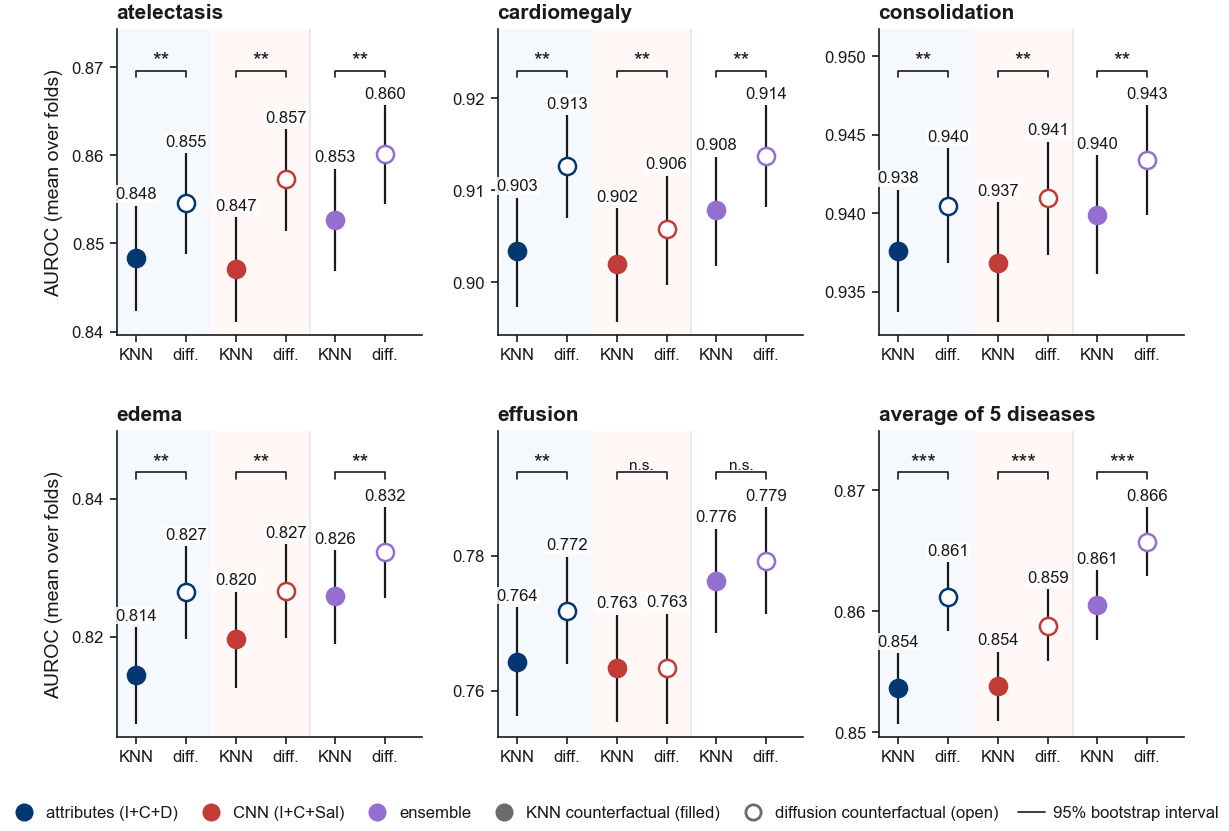

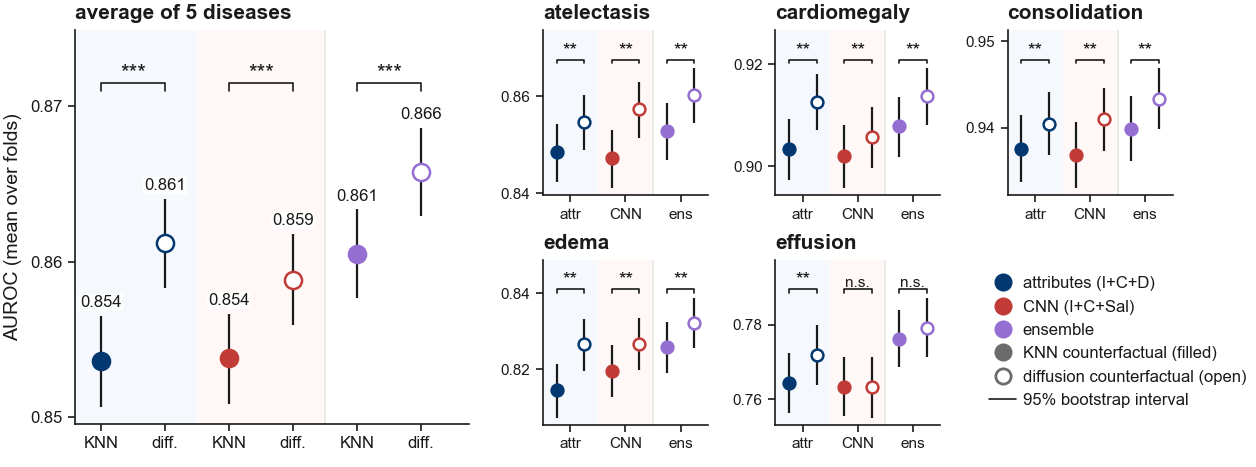

In [17]:
# ── Diffusion vs KNN, final models: the external bootstrap block ──
# The internal BOOT_* above are the diffusion arm alone; this block is the paired diffusion-KNN
# export, read the same way (deltas for the brackets, replicates for the whiskers).
EXT_FILES = {n: os.path.join(C2, f"bootstrap_diffusion_external{n}")
             for n in (".csv", "_replicates.csv")}


def load_external():
    missing = [p for p in EXT_FILES.values() if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError("diffusion-KNN bootstrap not found -- run section 4 of "
                                "bootstrapping_diffusion.ipynb:\n  " + "\n  ".join(missing))
    deltas = pd.read_csv(EXT_FILES[".csv"])
    reps   = pd.read_csv(EXT_FILES["_replicates.csv"], index_col="replicate")
    reps.columns = pd.MultiIndex.from_tuples([tuple(c.split("|", 1)) for c in reps.columns],
                                             names=["disease", "model"])
    return deltas, reps


EXT_DELTAS, EXT_REPS = load_external()
EXT_K = FINAL["k"]


def ext_row(comparison, disease):
    r = EXT_DELTAS[(EXT_DELTAS.comparison == comparison) & (EXT_DELTAS.disease == disease)]
    if len(r) != 1:
        raise KeyError(f"no diffusion-KNN bootstrap row for {comparison!r} / {disease!r}")
    return r.iloc[0]


def ext_interval(disease, cols, level=0.95):
    """Percentile interval of one model's mean-fold AUROC; `cols` is {disease: column}, since
    the best combiner can differ by disease. "AVERAGE" averages inside each replicate."""
    ds = list(cols) if disease == "AVERAGE" else [disease]
    v  = np.mean([EXT_REPS[d][cols[d]].to_numpy() for d in ds], axis=0)
    a  = (1 - level) / 2 * 100
    return np.percentile(v, [a, 100 - a])


ARM_ORDER = ["KNN", "diffusion"]                 # filled, then open
# (family, tick label, colour, bracket comparison in the external export)
ARM_PAIRS = [("attr", FINAL["attr"],             RAMP["attr"][2], f"attr {FINAL['attr']}"),
             ("cnn",  CNN_LABELS[FINAL["cnn"]],  RAMP["cnn"][1],  f"CNN {FINAL['cnn']}"),
             ("ens",  "ens",                     ENS,             "best ens (each arm's own)")]


def best_combiner(disease, source):
    """(combiner, AUROC) with the highest mean-fold AUROC -- the external block's pick."""
    e = load_ensemble(disease, EXT_K, source)
    if e is None:
        return None
    s = e["ens"]["auc_mean"]
    return s.idxmax(), float(s.max())


def arm_scores(disease):
    """{(family, arm): (AUROC, bootstrap column)}, or None until both arms have finished."""
    out = {}
    for arm in ARM_ORDER:
        src = ARMS[arm]
        a, c, b = load_attributes(disease, EXT_K, source=src), load_cnn(disease, EXT_K, source=src), \
                  best_combiner(disease, src)
        if a is None or c is None or b is None:
            return None
        out[("attr", arm)] = (per_fold_auc(a, f"MLP_{FINAL['attr']}_prob"),
                              f"{arm} {FINAL['attr']}@K{EXT_K}")
        out[("cnn", arm)]  = (per_fold_auc(c, f"cnn_{FINAL['cnn']}"),
                              f"{arm} CNN {FINAL['cnn']}@K{EXT_K}")
        out[("ens", arm)]  = (b[1], f"{arm} ENS {b[0]}@K{EXT_K}")
    return out


def arm_specs(diseases=DISEASES):
    """{panel: (AUROCs, intervals, brackets)} for every disease with both arms. No MSP: the
    question is diffusion against KNN, not either against the baseline. The
    AVERAGE panel joins once all diseases have both; its brackets only once the export carries
    AVERAGE rows (its own test), until then it is drawn without them."""
    scores = {d: s for d in diseases if (s := arm_scores(d)) is not None}
    keys   = [(fam, arm) for fam, *_ in ARM_PAIRS for arm in ARM_ORDER]
    cmps   = [(2 * j, 2 * j + 1, cmp, 0) for j, (_, _, _, cmp) in enumerate(ARM_PAIRS)]
    specs  = {d: (np.array([scores[d][k][0] for k in keys]),
                  np.array([ext_interval(d, {d: scores[d][k][1]}) for k in keys]), cmps)
              for d in scores}
    if len(scores) == len(DISEASES):
        specs["AVERAGE"] = (np.mean([specs[d][0] for d in scores], axis=0),
                            np.array([ext_interval("AVERAGE", {d: scores[d][k][1] for d in scores})
                                      for k in keys]),
                            cmps if "AVERAGE" in set(EXT_DELTAS.disease) else [])
    return specs


def arm_draw(specs):
    """draw(ax, panel, compact) for one arm panel, for the grid and key_figure alike."""
    keys   = [(fam, arm) for fam, *_ in ARM_PAIRS for arm in ARM_ORDER]
    colors = [c for _, _, c, _ in ARM_PAIRS for _ in ARM_ORDER]
    # The family is the colour and the band (and the legend); the tick only names the arm --
    # "I+C+D" / "I+C+Sal" side by side do not fit a 50 mm panel. A small panel names only the
    # family, once per pair: filled / open says which arm.
    names  = ["KNN" if arm == "KNN" else "diff." for _ in ARM_PAIRS for arm in ARM_ORDER]
    small  = [(2 * j + 0.5, lab) for j, lab in enumerate(["attr", "CNN", "ens"])]
    hollow = [i for i, (_, arm) in enumerate(keys) if arm == "diffusion"]

    def draw(ax, d, compact=False):
        h, ci, cmps = specs[d]
        points_panel(ax, d, h, ci, colors, colors, names, cmps, None, hollow=hollow,
                     bands=[(-1, 1.5, "attr"), (1.5, 3.5, "cnn")], values_above=True,
                     row_fn=ext_row, compact=compact, small_ticks=small)
        ax.axvline(3.5, color=HAIR, lw=LW["axis"], zorder=0)       # single models | ensembles
    return draw


def arm_legend():
    return [pt_handle(RAMP["attr"][2], RAMP["attr"][2], f"attributes ({FINAL['attr']})"),
            pt_handle(RAMP["cnn"][1], RAMP["cnn"][1], f"CNN ({CNN_LABELS[FINAL['cnn']]})"),
            pt_handle(ENS, ENS, "ensemble"),
            pt_handle(MUTED, MUTED, "KNN counterfactual (filled)"),
            pt_handle("white", MUTED, "diffusion counterfactual (open)"),
            INTERVAL]


NO_AVG_TEST = ("no AVERAGE rows in the diffusion-KNN export yet -- rerun bootstrapping_diffusion.ipynb "
               "for the average panel's test")


def arm_points(diseases=DISEASES, ncols=3, panel=POINTS_PANEL):
    specs = arm_specs(diseases)
    if not specs:
        print("no disease has both arms finished yet"); return
    # The grid shows the average panel only with its own test.
    panels = [d for d in specs if d != "AVERAGE" or specs[d][2]]
    if "AVERAGE" not in panels:
        print(NO_AVG_TEST)
    draw = arm_draw(specs)
    fig, axes = _grid(len(panels), ncols, panel=panel)
    for ax, d in zip(axes, panels):
        draw(ax, d)
    for ax in axes[::ncols]:
        ax.set_ylabel("AUROC (mean over folds)")
    corner_legend(fig, len(panels), ncols, arm_legend())
    return fig


def arm_points_key(diseases=DISEASES):
    """Key figure. The average panel is the figure here, so it is drawn even before its test
    exists -- without brackets, and with a printed warning."""
    specs = arm_specs(diseases)
    if "AVERAGE" not in specs:
        print("the arm key figure needs both arms on every disease"); return
    if not specs["AVERAGE"][2]:
        print(NO_AVG_TEST + " -- the key panel is drawn WITHOUT brackets")
    return key_figure(list(specs), arm_draw(specs), arm_legend())


save_fig(arm_points(), "aim2c_arm_points");
save_key_fig(arm_points_key(), "aim2c_arm_points");


## 2d. Summary table

The numbers behind the figures, one row per disease. `Δ MSP` is the gap the lollipops draw.

In [18]:
def summary(diseases=DISEASES, model="MLP", ks=None):
    rows = []
    for d in diseases:
        ref = load_attributes(d, FINAL["k"])
        if ref is None:
            continue
        r = {"disease": d, "n": len(ref)}
        r["MSP plain"] = per_fold_auc(ref, msp(ref, d, "standard"))
        r["MSP"] = per_fold_auc(ref, msp(ref, d))          # adjusted, as in 2a b

        a = best_attr(d, model, ks)
        if a:
            cfg, k, _s, adf, auc = a
            r["attr"], r["attr K"], r["attr AUROC"] = cfg, k, auc
            r["attr Δ MSP"] = auc - per_fold_auc(adf, msp(adf, d))

        c = best_cnn(d, ks)
        if c:
            key, k, cnn, col, _ = c
            m = cnn.merge(ref[["path", f"{d}_prob"]], on="path", how="inner")
            r["CNN"], r["CNN K"] = key, k
            r["CNN AUROC"] = per_fold_auc(m, col)
            r["CNN Δ MSP"] = r["CNN AUROC"] - per_fold_auc(m, msp(m, d))

        e = best_ensemble(d, ks)
        if e is not None:
            best_comp = max(e["attr"][1], e["cnn"][1])
            for meth in ENS_METHODS:
                if meth in e["ens"].index:
                    r[f"ens {meth} Δ comp"] = float(e["ens"].loc[meth, "auc_mean"]) - best_comp
        rows.append(r)
    return pd.DataFrame(rows).round(4)

summary()

,disease,n,MSP plain,MSP,attr,attr K,attr AUROC,attr Δ MSP,CNN,CNN K,CNN AUROC,CNN Δ MSP,ens mean Δ comp,ens rank Δ comp,ens lr Δ comp
0,atelectasis,20000,0.8221,0.8644,I+C+D,1,0.8546,-0.0098,dual_sal,1,0.8573,-0.0071,0.0021,0.0029,0.0023
1,cardiomegaly,20000,0.8923,0.9146,I+C+D,1,0.9126,-0.0020,dual_sal,1,0.9058,-0.0088,0.0004,0.0006,0.0011
2,consolidation,20000,0.9269,0.9474,I+C+D,1,0.9404,-0.0070,dual_sal,1,0.9410,-0.0065,0.0019,0.0024,0.0017
3,edema,20000,0.8097,0.8309,I+C+D,1,0.8265,-0.0043,dual_sal,1,0.8266,-0.0042,0.0054,0.0056,0.0052
4,effusion,20000,0.7810,0.7824,I+C+D,1,0.7717,-0.0107,dual_sal,1,0.7633,-0.0192,0.0072,0.0074,0.0065


## LaTeX captions

The figures carry no titles: their captions are written in LaTeX. This cell writes a draft
`figure` block for every figure this notebook saves to `FIG_DIR`, with the numbers that
come from the run (K, bootstrap replicates, star levels) filled in. Edit freely; rerunning
the notebook overwrites the file.


In [19]:
# Draft LaTeX captions, one figure block per saved figure. Run-dependent numbers are filled in
# from FINAL and the bootstrap, so the text cannot drift from the figures. Placeholders in
# <ANGLE> brackets are substituted below, which keeps the LaTeX free of doubled f-string braces.
_g = lambda grp: BOOT_DELTAS[BOOT_DELTAS.group == grp]

def best_model_tex():
    """Which model figure 2a draws, in words, from the bootstrap's picks."""
    kind = {"ENS": "the ensemble", "CNN": "the CNN"}
    picks = [BOOT_META["picks"][d]["best_all"].split()[0] for d in DISEASES]
    names = [kind.get(p, "the attribute model") for p in picks]
    if len(set(names)) == 1:
        return names[0] + " in every disease"
    return "; ".join(f"{d}: {m}" for d, m in zip(DISEASES, names))


FILL = {
    "<K>":       str(FINAL["k"]),
    "<KS>":      ", ".join(map(str, K_VALUES)),
    "<N>":       f"{BOOT_META['n_boot']:,}".replace(",", "{,}"),
    "<ND>":      str(len(DISEASES)),
    "<NCLAIMS>": str(_g("claims").comparison.nunique()),
    "<BEST>":    best_model_tex(),
    "<ND2>":     str(2 * len(DISEASES)),
    "<N2B>":     str(len(_g("2b"))),
    "<STARS>":   ", ".join(s + r"~$p_\mathrm{adj} < " + f"{t:g}" + "$" for t, s in STAR_LEVELS)
                 + ", n.s.\\ otherwise",
}

ARM = (r"Diffusion counterfactuals (FastDiME trajectories from the query), on the "
       r"20{,}000-image subset.")
K_DEF = (r"$K$ is the number of intensity levels pooled: $K=1$ is the strongest (high) edit "
         r"alone, $K=3$ adds the mid and low edits.")
MSP_LINES = (r"Grey lines: threshold-adjusted MSP (dashed) and plain $\max(p, 1-p)$ (dotted), "
             r"the untrained baselines.")
BOOT = (r"paired patient-level bootstrap (<N> replicates) of the mean-fold AUROC difference, "
        r"Holm-adjusted")
PAIRED = (r"Both arms use the same 20{,}000 images, patient-grouped folds and seed, so only the "
          r"source of the counterfactual differs.")

CAPTIONS = {
    "aim1a_attr_k_sweep":
        ARM + r" Attribute models: mean-fold AUROC of every input configuration, one line per "
        r"$K \in \{<KS>\}$. " + K_DEF + r" I: query attributes; C: counterfactual attributes; "
        r"D: query minus counterfactual. The shaded configuration (I) sees no counterfactual, "
        r"so its lines coincide across $K$. " + MSP_LINES + r" Each panel has its own $y$-range.",
    "aim1b_attr_vs_knn":
        r"Attribute models with diffusion (dashed, circles) and retrieved nearest-neighbour "
        r"(solid, squares) counterfactuals, at $K = 1$. " + PAIRED + r" The shaded configuration "
        r"(I) sees no counterfactual and is the control: the two arms must agree there. "
        + MSP_LINES,
    "aim1c_cnn_k_sweep":
        ARM + r" Image models: mean-fold AUROC of every CNN variant, one line per "
        r"$K \in \{<KS>\}$. " + K_DEF + r" I: query image; C: counterfactual image; Sal: saliency "
        r"maps; I+C uses one encoder per image. The shaded models see no counterfactual, so "
        r"their lines coincide across $K$. " + MSP_LINES + r" Each panel has its own $y$-range.",
    "aim1d_cnn_vs_knn":
        r"Image models with diffusion (dashed, circles) and retrieved nearest-neighbour (solid, "
        r"squares) counterfactuals, at $K = 1$. " + PAIRED + r" The shaded models (I, I+Sal) see "
        r"no counterfactual and are the control: the two arms must agree there. " + MSP_LINES,
    "aim1e_trajectory":
        ARM + r" Trajectory models, which see neither the counterfactual image nor C0's "
        r"probability on the query, only C0's probability along the diffusion trajectory. "
        r"Points: mean-fold AUROC of an MLP on each block of 32 hand-made trajectory features "
        r"(LEVEL, MONO, SHAPE, DYN) and on all of them (ALL), and, on the tinted band, of a 1D "
        r"CNN and a bidirectional GRU on the whole trajectory; whiskers: 95\% interval of a "
        r"patient-level bootstrap (<N> replicates). The models are independent, in the same "
        r"order in every panel. The last panel averages the <ND> diseases. Panel headers give "
        r"the number of images, C0's error rate and its split into false positives and false "
        r"negatives. $K = 1$. Each panel has its own $y$-range.",
    "aim1e_trajectory_short":
        ARM + r" Trajectory models, which see neither the counterfactual image nor C0's "
        r"probability on the query, only C0's probability along the diffusion trajectory: an MLP "
        r"on 32 hand-made trajectory features and, on the tinted band, a 1D CNN and a "
        r"bidirectional GRU on the whole trajectory. Points: mean-fold AUROC; whiskers: 95\% "
        r"interval of a patient-level bootstrap (<N> replicates). Brackets: paired bootstrap of "
        r"the AUROC difference on the same replicates, Holm-adjusted across the <ND> diseases "
        r"(average panel: a single test); <STARS>. $K = 1$. Each panel has its own $y$-range.",
    "aim1f_attr_blocks_bars":
        ARM + r" Adding the counterfactual to the attribute model, at $K = <K>$. Bars: mean-fold "
        r"AUROC of the query alone (I), with the counterfactual (I+C) and with the explicit "
        r"deltas (I+C+D); whiskers: 95\% bootstrap interval of each AUROC. Brackets: " + BOOT +
        r" across the <ND> diseases (disease panels) or across the <NCLAIMS> claims (average "
        r"panel); <STARS>. Both models are scored on the same patients, so overlapping "
        r"whiskers do not imply a non-significant difference. ",
    "aim1g_cnn_ladder_bars":
        ARM + r" Adding the counterfactual to the image model, at $K = <K>$. Bars: mean-fold "
        r"AUROC of the query image alone (I), with the counterfactual through a second encoder "
        r"(I+C) and with both saliency maps (I+C+Sal); whiskers: 95\% bootstrap interval of each "
        r"AUROC. Brackets: " + BOOT + r" across the <ND> diseases (disease panels) or across the "
        r"<NCLAIMS> claims (average panel); <STARS>. ",
    "aim2a_best_vs_msp":
        ARM + r"Final system against the adjusted MSP, at $K = <K>$. Gain of the final system's "
        r"strongest model (<BEST>) over the threshold-adjusted MSP, in mean-fold AUROC (a) and mean-fold E-AURC (b, "
        r"MSP minus model, so positive is better); the dashed line is the MSP. Tasks are "
        r"ordered by C0's threshold. Each label gives the gain and, in brackets, the percentage "
        r"of MSP's remaining gap to a perfect ranking that it closes: "
        r"$\mathrm{gain}/(1-\mathrm{AUROC}_\mathrm{MSP})$ in (a) and "
        r"$\mathrm{gain}/\mathrm{E\text{-}AURC}_\mathrm{MSP}$ in (b). The average row gives the "
        r"mean gain and the mean of the five per-task percentages. Whiskers: 95\% intervals of a "
        r"paired patient-level bootstrap (<N> replicates). Filled points and $*$: Holm-adjusted "
        r"$p < 0.05$. The correction runs across the <ND> tasks within each panel, separately "
        r"for (a) and (b), not across all <ND2> tests; the AUROC average is corrected across the "
        r"<NCLAIMS> thesis claims, the E-AURC average is a single test.",
    "aim2a_risk_coverage":
        ARM + r"Risk-coverage of the final system's strongest model against the adjusted MSP, for "
        r"the tasks with the largest and smallest AUROC gain. Top: C0's error rate among the "
        r"retained cases, most confident first; dotted: a perfect ranking. Bottom: the model's "
        r"risk minus MSP's (below zero: fewer errors retained). Pooled out-of-fold predictions; "
        r"the first 200 retained cases are not drawn.",
    "aim2b_ensemble":
        ARM + r" Combining the final attribute model and CNN ($K = <K>$). Bars: mean-fold AUROC "
        r"of the two components and three combiners --- the mean of the two probabilities, the "
        r"mean of their within-fold ranks, and a logistic regression fitted leave-one-fold-out. "
        r"Dashed line: the better component. Brackets: " + BOOT + r" across the <N2B> "
        r"combiner--disease tests of the figure, of each combiner against the better component; "
        r"<STARS>.",
    "aim2c_arm_points":
        r"The final system with retrieved nearest-neighbour (filled) and diffusion (open) "
        r"counterfactuals, at $K = <K>$: the attribute model (I+C+D), the CNN (I+C+Sal) and "
        r"the ensemble, whose combiner is each arm's own best. " + PAIRED + r" Points: mean-fold "
        r"AUROC; whiskers: 95\% bootstrap interval. Brackets: " + BOOT + r" within each disease "
        r"(average panel: across comparisons), diffusion against KNN; <STARS>. The ensemble "
        r"bracket compares two winners chosen after scoring. Each panel has its own $y$-range.",
}


POINTS_OF = {'aim1f_attr_blocks_bars': 'aim1f_attr_blocks_points', 'aim1g_cnn_ladder_bars': 'aim1g_cnn_ladder_points',
             'aim2b_ensemble': 'aim2b_ensemble_points'}

# The points versions of the comparison figures: the bar caption, reworded.
POINTS_NOTE = (r" Each panel has its own $y$-range, so compare models within a panel, not "
               r"heights across panels.")
for bars, points in POINTS_OF.items():
    if bars in CAPTIONS:
        CAPTIONS[points] = (CAPTIONS[bars].replace("Bars: mean-fold AUROC", "Points: mean-fold AUROC")
                            .replace("with (hatched)", "with (open points)") + POINTS_NOTE)

if "aim2b_ensemble_points" in CAPTIONS:
    CAPTIONS["aim2b_ensemble_points"] = CAPTIONS["aim2b_ensemble_points"].replace(
        "Dashed line: the better component.",
        r"Whiskers: 95\% bootstrap interval. Dash-dotted line: the better component.")

def latex_block(name, caption):
    for k, v in FILL.items():
        caption = caption.replace(k, v)
    stem = f"{FIG_PREFIX}_{name}"
    return (f"% {stem}\n\\begin{{figure}}[t]\n  \\centering\n"
            f"  \\includegraphics[width=\\textwidth]{{{FIG_DIR}/{stem}.pdf}}\n"
            f"  \\caption{{{caption}}}\n  \\label{{fig:{stem}}}\n\\end{{figure}}\n")


# Only figures that were actually saved, so the file never cites a missing PDF.
saved = [n for n in CAPTIONS if os.path.exists(os.path.join(FIG_DIR, f"{FIG_PREFIX}_{n}.pdf"))]
CAPTION_FILE = os.path.join(FIG_DIR, f"{FIG_PREFIX}_captions.tex")
with open(CAPTION_FILE, "w") as f:
    f.write(f"% Draft captions written by C2_evaluation*.ipynb ({FIG_PREFIX}). Overwritten on rerun.\n\n")
    f.write("\n".join(latex_block(n, CAPTIONS[n]) for n in saved))
print(f"wrote {len(saved)} captions to {CAPTION_FILE}"
      + (f"; no figure file for: {sorted(set(CAPTIONS) - set(saved))}" if len(saved) < len(CAPTIONS) else ""))


wrote 14 captions to figures/c2/diffusion_captions.tex
